In [2]:
import json
from pathlib import Path

print("Python is working!")
print("IPL Forensics environment ready!")

Python is working!
IPL Forensics environment ready!


In [3]:
import json
from pathlib import Path

# Location of our IPL JSON files
RAW_DIR = Path("../data/raw")

# Get the first JSON file
json_files = list(RAW_DIR.glob("*.json"))

print("Number of IPL matches:", len(json_files))
print("First file:", json_files[0].name)

# Load the first match
with open(json_files[0], "r", encoding="utf-8") as f:
    match = json.load(f)

print("Match loaded successfully!")
print("Top-level sections:", list(match.keys()))

Number of IPL matches: 1243
First file: 1082591.json
Match loaded successfully!
Top-level sections: ['meta', 'info', 'innings']


In [ ]:
import json
from pathlib import Path

# Location of our IPL JSON files
RAW_DIR = Path("../data/raw")

# Get the first JSON file
json_files = list(RAW_DIR.glob("*.json"))

print("Number of IPL matches:", len(json_files))
print("First file:", json_files[0].name)

# Load the first match
with open(json_files[0], "r", encoding="utf-8") as f:
    match = json.load(f)

print("Match loaded successfully!")
print("Top-level sections:", list(match.keys()))

Number of IPL matches: 1243
First file: 1082591.json
Match loaded successfully!
Top-level sections: ['meta', 'info', 'innings']


In [4]:
info = match["info"]

print("Teams:", info["teams"])
print("Date:", info["dates"])
print("Venue:", info.get("venue"))
print("City:", info.get("city"))
print("Toss:", info["toss"])
print("Outcome:", info["outcome"])

Teams: ['Sunrisers Hyderabad', 'Royal Challengers Bangalore']
Date: ['2017-04-05']
Venue: Rajiv Gandhi International Stadium, Uppal
City: Hyderabad
Toss: {'decision': 'field', 'winner': 'Royal Challengers Bangalore'}
Outcome: {'by': {'runs': 35}, 'winner': 'Sunrisers Hyderabad'}


In [5]:
innings = match["innings"]

print("Number of innings:", len(innings))

first_innings = innings[0]

print("Batting team:", first_innings["team"])
print("Number of overs:", len(first_innings["overs"]))

first_over = first_innings["overs"][0]

print("\nOver number:", first_over["over"])
print("Deliveries in this over:", len(first_over["deliveries"]))

print("\nFirst delivery:")
print(first_over["deliveries"][0])

Number of innings: 2
Batting team: Sunrisers Hyderabad
Number of overs: 20

Over number: 0
Deliveries in this over: 7

First delivery:
{'actual_delivery': '0.1', 'batter': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batter': 0, 'extras': 0, 'total': 0}}


In [6]:
import pandas as pd

rows = []

for file_path in json_files:
    with open(file_path, "r", encoding="utf-8") as f:
        match_data = json.load(f)

    info = match_data["info"]

    for innings_no, innings_data in enumerate(match_data["innings"], start=1):
        batting_team = innings_data["team"]

        for over_data in innings_data["overs"]:
            over_number = over_data["over"]

            for delivery_no, delivery in enumerate(
                over_data["deliveries"], start=1
            ):
                runs = delivery.get("runs", {})
                wickets = delivery.get("wickets", [])

                rows.append({
                    "match_id": file_path.stem,
                    "date": info.get("dates", [None])[0],
                    "venue": info.get("venue"),
                    "batting_team": batting_team,
                    "innings": innings_no,
                    "over": over_number,
                    "delivery": delivery_no,
                    "batter": delivery.get("batter"),
                    "bowler": delivery.get("bowler"),
                    "non_striker": delivery.get("non_striker"),
                    "runs_batter": runs.get("batter", 0),
                    "runs_extras": runs.get("extras", 0),
                    "runs_total": runs.get("total", 0),
                    "is_wicket": int(bool(wickets)),
                    "wicket_kind": wickets[0].get("kind") if wickets else None,
                    "player_out": wickets[0].get("player_out") if wickets else None
                })

deliveries_df = pd.DataFrame(rows)

print("Rows:", len(deliveries_df))
print("Columns:", len(deliveries_df.columns))

Rows: 295732
Columns: 16


In [7]:
print(deliveries_df.shape)

display(deliveries_df.head(10))

(295732, 16)


,match_id,date,venue,batting_team,innings,over,delivery,batter,bowler,non_striker,runs_batter,runs_extras,runs_total,is_wicket,wicket_kind,player_out
0,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,1,DA Warner,TS Mills,S Dhawan,0,0,0,0,NaN,NaN
1,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,2,DA Warner,TS Mills,S Dhawan,0,0,0,0,NaN,NaN
2,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,3,DA Warner,TS Mills,S Dhawan,4,0,4,0,NaN,NaN
3,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,4,DA Warner,TS Mills,S Dhawan,0,0,0,0,NaN,NaN
4,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,5,DA Warner,TS Mills,S Dhawan,0,2,2,0,NaN,NaN
5,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,6,S Dhawan,TS Mills,DA Warner,0,0,0,0,NaN,NaN
6,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,0,7,S Dhawan,TS Mills,DA Warner,0,1,1,0,NaN,NaN
7,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,1,1,S Dhawan,A Choudhary,DA Warner,1,0,1,0,NaN,NaN
8,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,1,2,DA Warner,A Choudhary,S Dhawan,4,0,4,0,NaN,NaN
9,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,1,1,3,DA Warner,A Choudhary,S Dhawan,0,1,1,0,NaN,NaN


In [8]:
# Sort deliveries in the correct match order
deliveries_df = deliveries_df.sort_values(
    ["match_id", "innings", "over", "delivery"]
).reset_index(drop=True)

# Cumulative score for each innings
deliveries_df["score"] = (
    deliveries_df
    .groupby(["match_id", "innings"])["runs_total"]
    .cumsum()
)

# Cumulative wickets
deliveries_df["wickets_lost"] = (
    deliveries_df
    .groupby(["match_id", "innings"])["is_wicket"]
    .cumsum()
)

# Runs scored in the previous 6 deliveries
deliveries_df["runs_last_6"] = (
    deliveries_df
    .groupby(["match_id", "innings"])["runs_total"]
    .rolling(6, min_periods=1)
    .sum()
    .reset_index(level=[0, 1], drop=True)
)

print("Match-state features created!")
display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "runs_total",
            "score",
            "wickets_lost",
            "runs_last_6"
        ]
    ].head(15)
)

Match-state features created!


,match_id,innings,over,delivery,runs_total,score,wickets_lost,runs_last_6
0,1082591,1,0,1,0,0,0,0.0
1,1082591,1,0,2,0,0,0,0.0
2,1082591,1,0,3,4,4,0,4.0
3,1082591,1,0,4,0,4,0,4.0
4,1082591,1,0,5,2,6,0,6.0
5,1082591,1,0,6,0,6,0,6.0
6,1082591,1,0,7,1,7,0,7.0
7,1082591,1,1,1,1,8,0,8.0
8,1082591,1,1,2,4,12,0,8.0
9,1082591,1,1,3,1,13,0,9.0


In [9]:
# Number of deliveries in each innings so far
deliveries_df["balls_bowled"] = (
    deliveries_df
    .groupby(["match_id", "innings"])
    .cumcount() + 1
)

# Approximate overs completed
deliveries_df["overs_completed"] = (
    deliveries_df["balls_bowled"] / 6
)

# Current run rate
deliveries_df["current_run_rate"] = (
    deliveries_df["score"] /
    deliveries_df["overs_completed"]
)

# Identify innings phase
def get_phase(over):
    if over < 6:
        return "Powerplay"
    elif over < 15:
        return "Middle"
    else:
        return "Death"

deliveries_df["phase"] = deliveries_df["over"].apply(get_phase)

print("Run-rate and phase features created!")

display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "score",
            "wickets_lost",
            "balls_bowled",
            "current_run_rate",
            "phase"
        ]
    ].head(15)
)

Run-rate and phase features created!


,match_id,innings,over,score,wickets_lost,balls_bowled,current_run_rate,phase
0,1082591,1,0,0,0,1,0.000000,Powerplay
1,1082591,1,0,0,0,2,0.000000,Powerplay
2,1082591,1,0,4,0,3,8.000000,Powerplay
3,1082591,1,0,4,0,4,6.000000,Powerplay
4,1082591,1,0,6,0,5,7.200000,Powerplay
5,1082591,1,0,6,0,6,6.000000,Powerplay
6,1082591,1,0,7,0,7,6.000000,Powerplay
7,1082591,1,1,8,0,8,6.000000,Powerplay
8,1082591,1,1,12,0,9,8.000000,Powerplay
9,1082591,1,1,13,0,10,7.800000,Powerplay


In [10]:
# Get the final score of each innings
innings_scores = (
    deliveries_df
    .groupby(["match_id", "innings"])["runs_total"]
    .sum()
    .reset_index()
)

innings_scores = innings_scores.rename(
    columns={"runs_total": "innings_total"}
)

# Show some innings totals
display(innings_scores.head(10))

,match_id,innings,innings_total
0,1082591,1,207
1,1082591,2,172
2,1082592,1,184
3,1082592,2,187
4,1082593,1,183
5,1082593,2,184
6,1082594,1,163
7,1082594,2,164
8,1082595,1,157
9,1082595,2,142


In [11]:
# Create a lookup for first-innings totals
first_innings_scores = (
    innings_scores[innings_scores["innings"] == 1]
    [["match_id", "innings_total"]]
    .rename(columns={"innings_total": "target_score"})
)

# Add target to every delivery
deliveries_df = deliveries_df.merge(
    first_innings_scores,
    on="match_id",
    how="left"
)

# Target is one more than the first innings score
deliveries_df["target"] = deliveries_df["target_score"] + 1

# Required runs for the chasing team
deliveries_df["runs_required"] = (
    deliveries_df["target"] - deliveries_df["score"]
)

# Only meaningful for second innings
deliveries_df.loc[
    deliveries_df["innings"] == 1,
    "runs_required"
] = None

print("Chasing features created!")

display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "score",
            "target",
            "runs_required"
        ]
    ].head(20)
)

Chasing features created!


,match_id,innings,over,score,target,runs_required
0,1082591,1,0,0,208,NaN
1,1082591,1,0,0,208,NaN
2,1082591,1,0,4,208,NaN
3,1082591,1,0,4,208,NaN
4,1082591,1,0,6,208,NaN
5,1082591,1,0,6,208,NaN
6,1082591,1,0,7,208,NaN
7,1082591,1,1,8,208,NaN
8,1082591,1,1,12,208,NaN
9,1082591,1,1,13,208,NaN


In [12]:
# Boundary indicators
deliveries_df["is_four"] = (
    deliveries_df["runs_batter"] == 4
).astype(int)

deliveries_df["is_six"] = (
    deliveries_df["runs_batter"] == 6
).astype(int)

# Dot-ball indicator
deliveries_df["is_dot"] = (
    deliveries_df["runs_total"] == 0
).astype(int)

# Wicket indicator already exists as is_wicket

# Recent events in the last 6 deliveries
group_cols = ["match_id", "innings"]

deliveries_df["fours_last_6"] = (
    deliveries_df.groupby(group_cols)["is_four"]
    .rolling(6, min_periods=1)
    .sum()
    .reset_index(level=group_cols, drop=True)
)

deliveries_df["sixes_last_6"] = (
    deliveries_df.groupby(group_cols)["is_six"]
    .rolling(6, min_periods=1)
    .sum()
    .reset_index(level=group_cols, drop=True)
)

deliveries_df["wickets_last_6"] = (
    deliveries_df.groupby(group_cols)["is_wicket"]
    .rolling(6, min_periods=1)
    .sum()
    .reset_index(level=group_cols, drop=True)
)

print("Event features created!")

display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "runs_total",
            "is_four",
            "is_six",
            "is_dot",
            "is_wicket",
            "fours_last_6",
            "sixes_last_6",
            "wickets_last_6"
        ]
    ].head(20)
)

Event features created!


,match_id,innings,over,delivery,runs_total,is_four,is_six,is_dot,is_wicket,fours_last_6,sixes_last_6,wickets_last_6
0,1082591,1,0,1,0,0,0,1,0,0.0,0.0,0.0
1,1082591,1,0,2,0,0,0,1,0,0.0,0.0,0.0
2,1082591,1,0,3,4,1,0,0,0,1.0,0.0,0.0
3,1082591,1,0,4,0,0,0,1,0,1.0,0.0,0.0
4,1082591,1,0,5,2,0,0,0,0,1.0,0.0,0.0
5,1082591,1,0,6,0,0,0,1,0,1.0,0.0,0.0
6,1082591,1,0,7,1,0,0,0,0,1.0,0.0,0.0
7,1082591,1,1,1,1,0,0,0,0,1.0,0.0,0.0
8,1082591,1,1,2,4,1,0,0,0,1.0,0.0,0.0
9,1082591,1,1,3,1,0,0,0,0,1.0,0.0,0.0


In [13]:
# Recent scoring compared with the innings' overall scoring rate

deliveries_df["recent_run_rate"] = (
    deliveries_df["runs_last_6"] / 1
)

deliveries_df["momentum_signal"] = (
    deliveries_df["recent_run_rate"]
    - deliveries_df["current_run_rate"]
)

print("Momentum signal created!")

display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "score",
            "current_run_rate",
            "runs_last_6",
            "momentum_signal"
        ]
    ].head(20)
)

Momentum signal created!


,match_id,innings,over,score,current_run_rate,runs_last_6,momentum_signal
0,1082591,1,0,0,0.000000,0.0,0.000000
1,1082591,1,0,0,0.000000,0.0,0.000000
2,1082591,1,0,4,8.000000,4.0,-4.000000
3,1082591,1,0,4,6.000000,4.0,-2.000000
4,1082591,1,0,6,7.200000,6.0,-1.200000
5,1082591,1,0,6,6.000000,6.0,0.000000
6,1082591,1,0,7,6.000000,7.0,1.000000
7,1082591,1,1,8,6.000000,8.0,2.000000
8,1082591,1,1,12,8.000000,8.0,0.000000
9,1082591,1,1,13,7.800000,9.0,1.200000


In [14]:
# Save our delivery-level dataset
output_path = Path("../data/processed/ipl_deliveries.csv")

deliveries_df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print(f"Location: {output_path}")
print(f"Rows: {len(deliveries_df):,}")
print(f"Columns: {len(deliveries_df.columns)}")

Dataset saved successfully!
Location: ..\data\processed\ipl_deliveries.csv
Rows: 295,732
Columns: 34


In [15]:
# Add the winning team to every delivery

match_winners = {}

for file_path in json_files:
    with open(file_path, "r", encoding="utf-8") as f:
        match_data = json.load(f)

    outcome = match_data["info"].get("outcome", {})

    winner = outcome.get("winner")

    if winner:
        match_winners[file_path.stem] = winner

deliveries_df["winner"] = deliveries_df["match_id"].map(match_winners)

print("Winner information added!")
print("Matches with winner information:",
      deliveries_df["winner"].notna().sum())

Winner information added!
Matches with winner information: 290752


In [16]:
display(
    deliveries_df[
        ["match_id", "innings", "batting_team", "score", "winner"]
    ].head(10)
)

,match_id,innings,batting_team,score,winner
0,1082591,1,Sunrisers Hyderabad,0,Sunrisers Hyderabad
1,1082591,1,Sunrisers Hyderabad,0,Sunrisers Hyderabad
2,1082591,1,Sunrisers Hyderabad,4,Sunrisers Hyderabad
3,1082591,1,Sunrisers Hyderabad,4,Sunrisers Hyderabad
4,1082591,1,Sunrisers Hyderabad,6,Sunrisers Hyderabad
5,1082591,1,Sunrisers Hyderabad,6,Sunrisers Hyderabad
6,1082591,1,Sunrisers Hyderabad,7,Sunrisers Hyderabad
7,1082591,1,Sunrisers Hyderabad,8,Sunrisers Hyderabad
8,1082591,1,Sunrisers Hyderabad,12,Sunrisers Hyderabad
9,1082591,1,Sunrisers Hyderabad,13,Sunrisers Hyderabad


In [17]:
# Keep only rows where we know the winner
ml_df = deliveries_df.dropna(subset=["winner"]).copy()

# Did the batting team eventually win this match?
ml_df["batting_team_won"] = (
    ml_df["batting_team"] == ml_df["winner"]
).astype(int)

# Select our initial match-state features
features = [
    "score",
    "wickets_lost",
    "balls_bowled",
    "current_run_rate",
    "runs_last_6",
    "is_four",
    "is_six",
    "is_dot",
    "wickets_last_6"
]

X = ml_df[features].fillna(0)
y = ml_df["batting_team_won"]

print("ML dataset created!")
print("Rows:", len(X))
print("Features:", X.columns.tolist())
print("Target:", y.name)

ML dataset created!
Rows: 290752
Features: ['score', 'wickets_lost', 'balls_bowled', 'current_run_rate', 'runs_last_6', 'is_four', 'is_six', 'is_dot', 'wickets_last_6']
Target: batting_team_won


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Get unique matches
match_ids = ml_df["match_id"].unique()

# Split matches, not deliveries
train_matches, test_matches = train_test_split(
    match_ids,
    test_size=0.20,
    random_state=42
)

train_data = ml_df[ml_df["match_id"].isin(train_matches)]
test_data = ml_df[ml_df["match_id"].isin(test_matches)]

X_train = train_data[features].fillna(0)
y_train = train_data["batting_team_won"]

X_test = test_data[features].fillna(0)
y_test = test_data["batting_team_won"]

print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training matches: 974
Testing matches: 244
Training rows: 232323
Testing rows: 58429


In [19]:
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [20]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")


Test Accuracy: 63.55%


In [21]:
# Predict probability of batting team winning
win_probabilities = model.predict_proba(X_test)[:, 1]

test_data = test_data.copy()
test_data["win_probability"] = win_probabilities

display(
    test_data[
        [
            "match_id",
            "innings",
            "over",
            "score",
            "wickets_lost",
            "win_probability"
        ]
    ].head(20)
)

,match_id,innings,over,score,wickets_lost,win_probability
2355,1082601,1,0,0,0,0.504890
2356,1082601,1,0,4,0,0.511964
2357,1082601,1,0,4,0,0.484603
2358,1082601,1,0,6,0,0.541152
2359,1082601,1,0,10,0,0.604862
2360,1082601,1,0,10,0,0.576120
2361,1082601,1,1,12,0,0.573670
2362,1082601,1,1,13,0,0.585605
2363,1082601,1,1,13,0,0.586510
2364,1082601,1,1,13,0,0.529283


In [22]:
# Sort test data in match order
test_data = test_data.sort_values(
    ["match_id", "innings", "over", "delivery"]
).copy()

# Change in win probability from the previous delivery
test_data["probability_change"] = (
    test_data
    .groupby(["match_id", "innings"])["win_probability"]
    .diff()
)

# Absolute size of the change
test_data["change_magnitude"] = (
    test_data["probability_change"].abs()
)

# Show the biggest changes
turning_points = (
    test_data
    .sort_values("change_magnitude", ascending=False)
    .head(20)
)

display(
    turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "score",
            "wickets_lost",
            "runs_total",
            "is_wicket",
            "win_probability",
            "probability_change"
        ]
    ]
)

,match_id,innings,over,delivery,batting_team,batter,bowler,score,wickets_lost,runs_total,is_wicket,win_probability,probability_change
115713,1426273,2,14,6,Delhi Capitals,Lalit Yadav,T Natarajan,166,6,0,1,0.135738,-0.503110
131241,1473466,2,15,3,Delhi Capitals,KL Rahul,KV Sharma,160,6,0,1,0.136034,-0.492817
136827,1473490,2,15,6,Rajasthan Royals,SO Hetmyer,Harshit Rana,163,6,0,1,0.163240,-0.484629
106980,1370352,2,14,5,Mumbai Indians,Vishnu Vinod,MM Sharma,156,6,0,1,0.139241,-0.483828
129478,1473459,1,19,7,Punjab Kings,Shashank Singh,M Pathirana,219,6,3,0,0.778573,0.452153
130776,1473464,2,16,2,Sunrisers Hyderabad,Abhishek Sharma,Arshdeep Singh,222,2,0,1,0.912620,0.446699
92479,1359487,2,16,2,Kolkata Knight Riders,SP Narine,Rashid Khan,155,6,0,1,0.227796,-0.431618
153848,1529296,1,14,3,Lucknow Super Giants,Akshat Raghuwanshi,J Overton,147,6,0,1,0.209531,-0.406376
129470,1473459,1,18,5,Punjab Kings,Shashank Singh,KK Ahmed,206,6,4,0,0.852245,0.390787
115697,1426273,2,12,2,Delhi Capitals,T Stubbs,Nithish Kumar Reddy,154,5,0,1,0.387592,-0.383417


In [23]:
# Turning Point Score = size of the win-probability swing
test_data["turning_point_score"] = (
    test_data["probability_change"].abs() * 100
)

# Keep only strong candidate turning points
major_turning_points = (
    test_data[
        test_data["turning_point_score"] >= 15
    ]
    .sort_values("turning_point_score", ascending=False)
)

print(
    "Major candidate turning points:",
    len(major_turning_points)
)

display(
    major_turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "runs_total",
            "is_wicket",
            "score",
            "wickets_lost",
            "win_probability",
            "probability_change",
            "turning_point_score"
        ]
    ].head(20)
)

Major candidate turning points: 886


,match_id,innings,over,delivery,batting_team,batter,bowler,runs_total,is_wicket,score,wickets_lost,win_probability,probability_change,turning_point_score
115713,1426273,2,14,6,Delhi Capitals,Lalit Yadav,T Natarajan,0,1,166,6,0.135738,-0.503110,50.310972
131241,1473466,2,15,3,Delhi Capitals,KL Rahul,KV Sharma,0,1,160,6,0.136034,-0.492817,49.281685
136827,1473490,2,15,6,Rajasthan Royals,SO Hetmyer,Harshit Rana,0,1,163,6,0.163240,-0.484629,48.462949
106980,1370352,2,14,5,Mumbai Indians,Vishnu Vinod,MM Sharma,0,1,156,6,0.139241,-0.483828,48.382790
129478,1473459,1,19,7,Punjab Kings,Shashank Singh,M Pathirana,3,0,219,6,0.778573,0.452153,45.215272
130776,1473464,2,16,2,Sunrisers Hyderabad,Abhishek Sharma,Arshdeep Singh,0,1,222,2,0.912620,0.446699,44.669943
92479,1359487,2,16,2,Kolkata Knight Riders,SP Narine,Rashid Khan,0,1,155,6,0.227796,-0.431618,43.161808
153848,1529296,1,14,3,Lucknow Super Giants,Akshat Raghuwanshi,J Overton,0,1,147,6,0.209531,-0.406376,40.637639
129470,1473459,1,18,5,Punjab Kings,Shashank Singh,KK Ahmed,4,0,206,6,0.852245,0.390787,39.078709
115697,1426273,2,12,2,Delhi Capitals,T Stubbs,Nithish Kumar Reddy,0,1,154,5,0.387592,-0.383417,38.341698


In [24]:
def classify_event(row):
    if row["is_wicket"] == 1:
        return "WICKET"
    elif row["runs_batter"] == 6:
        return "SIX"
    elif row["runs_batter"] == 4:
        return "FOUR"
    elif row["runs_total"] == 0:
        return "DOT BALL"
    elif row["runs_total"] >= 3:
        return "SCORING BURST"
    else:
        return "OTHER"


major_turning_points = major_turning_points.copy()

major_turning_points["event_type"] = (
    major_turning_points.apply(classify_event, axis=1)
)

display(
    major_turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batter",
            "bowler",
            "event_type",
            "runs_total",
            "score",
            "wickets_lost",
            "win_probability",
            "probability_change",
            "turning_point_score"
        ]
    ].head(20)
)

,match_id,innings,over,delivery,batter,bowler,event_type,runs_total,score,wickets_lost,win_probability,probability_change,turning_point_score
115713,1426273,2,14,6,Lalit Yadav,T Natarajan,WICKET,0,166,6,0.135738,-0.503110,50.310972
131241,1473466,2,15,3,KL Rahul,KV Sharma,WICKET,0,160,6,0.136034,-0.492817,49.281685
136827,1473490,2,15,6,SO Hetmyer,Harshit Rana,WICKET,0,163,6,0.163240,-0.484629,48.462949
106980,1370352,2,14,5,Vishnu Vinod,MM Sharma,WICKET,0,156,6,0.139241,-0.483828,48.382790
129478,1473459,1,19,7,Shashank Singh,M Pathirana,SCORING BURST,3,219,6,0.778573,0.452153,45.215272
130776,1473464,2,16,2,Abhishek Sharma,Arshdeep Singh,WICKET,0,222,2,0.912620,0.446699,44.669943
92479,1359487,2,16,2,SP Narine,Rashid Khan,WICKET,0,155,6,0.227796,-0.431618,43.161808
153848,1529296,1,14,3,Akshat Raghuwanshi,J Overton,WICKET,0,147,6,0.209531,-0.406376,40.637639
129470,1473459,1,18,5,Shashank Singh,KK Ahmed,FOUR,4,206,6,0.852245,0.390787,39.078709
115697,1426273,2,12,2,T Stubbs,Nithish Kumar Reddy,WICKET,0,154,5,0.387592,-0.383417,38.341698


In [25]:
# Sort deliveries correctly
deliveries_df = deliveries_df.sort_values(
    ["match_id", "innings", "over", "delivery"]
).reset_index(drop=True)

# Previous state before the current delivery
group_cols = ["match_id", "innings"]

deliveries_df["score_before"] = (
    deliveries_df.groupby(group_cols)["runs_total"]
    .cumsum()
    - deliveries_df["runs_total"]
)

deliveries_df["wickets_before"] = (
    deliveries_df.groupby(group_cols)["is_wicket"]
    .cumsum()
    - deliveries_df["is_wicket"]
)

deliveries_df["runs_last_6_before"] = (
    deliveries_df.groupby(group_cols)["runs_total"]
    .shift(1)
    .rolling(6, min_periods=1)
    .sum()
)

print("Pre-ball state created!")

Pre-ball state created!


In [26]:
display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batter",
            "bowler",
            "score_before",
            "wickets_before",
            "runs_total"
        ]
    ].head(15)
)

,match_id,innings,over,delivery,batter,bowler,score_before,wickets_before,runs_total
0,1082591,1,0,1,DA Warner,TS Mills,0,0,0
1,1082591,1,0,2,DA Warner,TS Mills,0,0,0
2,1082591,1,0,3,DA Warner,TS Mills,0,0,4
3,1082591,1,0,4,DA Warner,TS Mills,4,0,0
4,1082591,1,0,5,DA Warner,TS Mills,4,0,2
5,1082591,1,0,6,S Dhawan,TS Mills,6,0,0
6,1082591,1,0,7,S Dhawan,TS Mills,6,0,1
7,1082591,1,1,1,S Dhawan,A Choudhary,7,0,1
8,1082591,1,1,2,DA Warner,A Choudhary,8,0,4
9,1082591,1,1,3,DA Warner,A Choudhary,12,0,1


In [28]:
ml_df = deliveries_df.dropna(subset=["winner"]).copy()

ml_df["batting_team_won"] = (
    ml_df["batting_team"] == ml_df["winner"]
).astype(int)

features = [
    "score_before",
    "wickets_before",
    "balls_bowled",
    "runs_last_6_before"
]

X = ml_df[features].fillna(0)
y = ml_df["batting_team_won"]

print("ML dataset ready!")
print("Features:", features)
print("Rows:", len(ml_df))

ML dataset ready!
Features: ['score_before', 'wickets_before', 'balls_bowled', 'runs_last_6_before']
Rows: 290752


In [29]:
from sklearn.model_selection import train_test_split

match_ids = ml_df["match_id"].unique()

train_matches, test_matches = train_test_split(
    match_ids,
    test_size=0.20,
    random_state=42
)

train_data = ml_df[
    ml_df["match_id"].isin(train_matches)
]

test_data = ml_df[
    ml_df["match_id"].isin(test_matches)
]

X_train = train_data[features].fillna(0)
y_train = train_data["batting_team_won"]

X_test = test_data[features].fillna(0)
y_test = test_data["batting_team_won"]

print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training matches: 974
Testing matches: 244
Training rows: 232323
Testing rows: 58429


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model_corrected = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model_corrected.fit(X_train, y_train)

y_pred = model_corrected.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Corrected model trained successfully!")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Corrected model trained successfully!
Accuracy: 63.81%

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.60      0.63     29688
           1       0.62      0.68      0.65     28741

    accuracy                           0.64     58429
   macro avg       0.64      0.64      0.64     58429
weighted avg       0.64      0.64      0.64     58429



In [31]:
win_probabilities = model_corrected.predict_proba(X_test)[:, 1]

test_data = test_data.copy()

test_data["win_probability"] = win_probabilities

display(
    test_data[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "score_before",
            "wickets_before",
            "win_probability"
        ]
    ].head(20)
)

,match_id,innings,over,delivery,batting_team,score_before,wickets_before,win_probability
2355,1082601,1,0,1,Kings XI Punjab,0,0,0.497442
2356,1082601,1,0,2,Kings XI Punjab,0,0,0.526536
2357,1082601,1,0,3,Kings XI Punjab,4,0,0.519375
2358,1082601,1,0,4,Kings XI Punjab,4,0,0.514187
2359,1082601,1,0,5,Kings XI Punjab,6,0,0.528854
2360,1082601,1,0,6,Kings XI Punjab,10,0,0.569424
2361,1082601,1,1,1,Kings XI Punjab,10,0,0.558106
2362,1082601,1,1,2,Kings XI Punjab,12,0,0.572811
2363,1082601,1,1,3,Kings XI Punjab,13,0,0.561087
2364,1082601,1,1,4,Kings XI Punjab,13,0,0.558857


Matplotlib is building the font cache; this may take a moment.


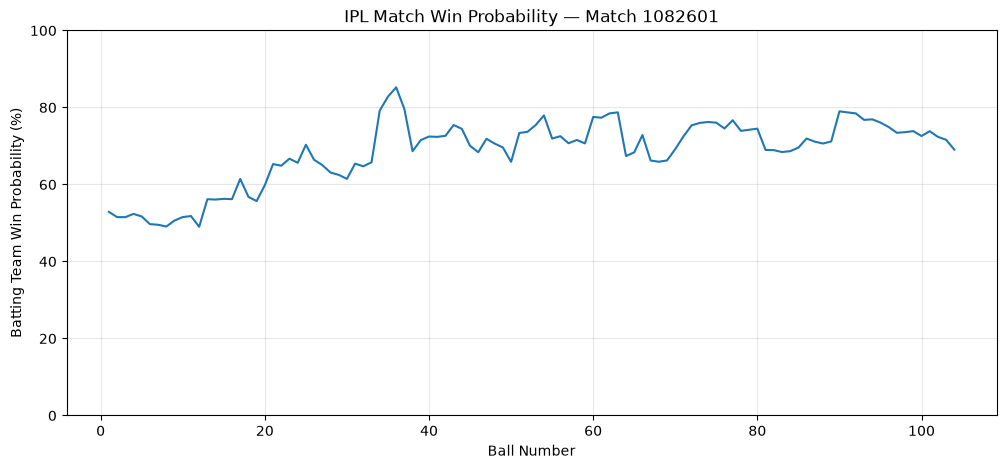

In [32]:
import matplotlib.pyplot as plt

# Pick one match from the test set
selected_match = test_data["match_id"].iloc[0]

match_plot = test_data[
    (test_data["match_id"] == selected_match) &
    (test_data["innings"] == 2)
].copy()

match_plot["ball_number"] = range(1, len(match_plot) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    match_plot["ball_number"],
    match_plot["win_probability"] * 100
)

plt.xlabel("Ball Number")
plt.ylabel("Batting Team Win Probability (%)")
plt.title(f"IPL Match Win Probability — Match {selected_match}")

plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

In [33]:
test_data = test_data.sort_values(
    ["match_id", "innings", "over", "delivery"]
).copy()

# Probability change from one ball to the next
test_data["probability_change"] = (
    test_data
    .groupby(["match_id", "innings"])["win_probability"]
    .diff()
)

# Absolute size of the change
test_data["change_magnitude"] = (
    test_data["probability_change"].abs()
)

# Top 20 biggest changes
turning_points = (
    test_data
    .dropna(subset=["probability_change"])
    .sort_values("change_magnitude", ascending=False)
    .head(20)
)

display(
    turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "score_before",
            "wickets_before",
            "runs_total",
            "is_wicket",
            "win_probability",
            "probability_change",
            "change_magnitude"
        ]
    ]
)

,match_id,innings,over,delivery,batting_team,batter,bowler,score_before,wickets_before,runs_total,is_wicket,win_probability,probability_change,change_magnitude
136828,1473490,2,15,7,Rajasthan Royals,SB Dubey,Harshit Rana,163,6,1,0,0.093084,-0.589502,0.589502
73029,1304053,1,19,4,Chennai Super Kings,DJ Bravo,AJ Tye,203,7,1,0,0.336436,-0.589135,0.589135
115714,1426273,2,15,1,Delhi Capitals,RR Pant,Nithish Kumar Reddy,166,6,1,0,0.050038,-0.562882,0.562882
114698,1426269,1,19,6,Kolkata Knight Riders,RK Singh,KR Sen,222,6,1,0,0.887307,0.557583,0.557583
130656,1473464,1,17,5,Punjab Kings,MP Stoinis,HV Patel,207,6,1,0,0.308150,-0.555962,0.555962
106981,1370352,2,14,6,Mumbai Indians,CJ Jordan,MM Sharma,156,6,0,0,0.138301,-0.535858,0.535858
92480,1359487,2,16,3,Kolkata Knight Riders,SN Thakur,Rashid Khan,155,6,0,1,0.109173,-0.520626,0.520626
142884,1527679,1,19,6,Sunrisers Hyderabad,Shivang Kumar,B Muzarabani,222,7,4,0,0.338477,-0.517025,0.517025
142880,1527679,1,19,2,Sunrisers Hyderabad,H Klaasen,B Muzarabani,212,6,2,0,0.901991,0.510929,0.510929
96795,1359505,1,19,2,Punjab Kings,JM Sharma,JP Behrendorff,203,6,0,0,0.870717,0.504074,0.504074


In [34]:
def classify_event(row):
    if row["is_wicket"] == 1:
        return "WICKET"
    elif row["runs_batter"] == 6:
        return "SIX"
    elif row["runs_batter"] == 4:
        return "FOUR"
    elif row["runs_total"] == 0:
        return "DOT BALL"
    elif row["runs_total"] >= 3:
        return "SCORING BURST"
    else:
        return "OTHER"


turning_points = turning_points.copy()

turning_points["event_type"] = (
    turning_points.apply(classify_event, axis=1)
)

display(
    turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batter",
            "bowler",
            "event_type",
            "runs_total",
            "is_wicket",
            "score_before",
            "wickets_before",
            "win_probability",
            "probability_change",
            "change_magnitude"
        ]
    ]
)

,match_id,innings,over,delivery,batter,bowler,event_type,runs_total,is_wicket,score_before,wickets_before,win_probability,probability_change,change_magnitude
136828,1473490,2,15,7,SB Dubey,Harshit Rana,OTHER,1,0,163,6,0.093084,-0.589502,0.589502
73029,1304053,1,19,4,DJ Bravo,AJ Tye,OTHER,1,0,203,7,0.336436,-0.589135,0.589135
115714,1426273,2,15,1,RR Pant,Nithish Kumar Reddy,OTHER,1,0,166,6,0.050038,-0.562882,0.562882
114698,1426269,1,19,6,RK Singh,KR Sen,OTHER,1,0,222,6,0.887307,0.557583,0.557583
130656,1473464,1,17,5,MP Stoinis,HV Patel,OTHER,1,0,207,6,0.308150,-0.555962,0.555962
106981,1370352,2,14,6,CJ Jordan,MM Sharma,DOT BALL,0,0,156,6,0.138301,-0.535858,0.535858
92480,1359487,2,16,3,SN Thakur,Rashid Khan,WICKET,0,1,155,6,0.109173,-0.520626,0.520626
142884,1527679,1,19,6,Shivang Kumar,B Muzarabani,FOUR,4,0,222,7,0.338477,-0.517025,0.517025
142880,1527679,1,19,2,H Klaasen,B Muzarabani,OTHER,2,0,212,6,0.901991,0.510929,0.510929
96795,1359505,1,19,2,JM Sharma,JP Behrendorff,DOT BALL,0,0,203,6,0.870717,0.504074,0.504074


In [35]:
# Select the match containing the biggest turning point
selected_match = turning_points.iloc[0]["match_id"]

match_events = turning_points[
    turning_points["match_id"] == selected_match
].copy()

print("======================================")
print("        IPL MATCH AUTOPSY")
print("======================================")
print("Match ID:", selected_match)
print()

# Show the biggest turning points
display(
    match_events[
        [
            "innings",
            "over",
            "delivery",
            "batter",
            "bowler",
            "event_type",
            "runs_total",
            "is_wicket",
            "score_before",
            "wickets_before",
            "win_probability",
            "probability_change",
            "change_magnitude"
        ]
    ].sort_values(
        "change_magnitude",
        ascending=False
    )
)

        IPL MATCH AUTOPSY
Match ID: 1473490



,innings,over,delivery,batter,bowler,event_type,runs_total,is_wicket,score_before,wickets_before,win_probability,probability_change,change_magnitude
136828,2,15,7,SB Dubey,Harshit Rana,OTHER,1,0,163,6,0.093084,-0.589502,0.589502


In [36]:
def impact_level(change):
    change = abs(change)

    if change >= 0.20:
        return "CRITICAL"
    elif change >= 0.15:
        return "HIGH"
    elif change >= 0.10:
        return "MEDIUM"
    else:
        return "LOW"


match_events["impact_level"] = (
    match_events["probability_change"]
    .apply(impact_level)
)

for _, row in match_events.head(10).iterrows():

    direction = (
        "increased"
        if row["probability_change"] > 0
        else "decreased"
    )

    print("======================================")
    print("TURNING POINT")
    print("======================================")
    print(
        f"Innings {row['innings']} | "
        f"Over {row['over']}.{row['delivery']}"
    )
    print(f"Batter: {row['batter']}")
    print(f"Bowler: {row['bowler']}")
    print(f"Event: {row['event_type']}")
    print(
        f"Win probability {direction} by "
        f"{abs(row['probability_change']) * 100:.2f} percentage points"
    )
    print(f"Impact: {row['impact_level']}")
    print()

TURNING POINT
Innings 2 | Over 15.7
Batter: SB Dubey
Bowler: Harshit Rana
Event: OTHER
Win probability decreased by 58.95 percentage points
Impact: CRITICAL



In [37]:
critical = deliveries_df[
    (deliveries_df["match_id"] == selected_match) &
    (deliveries_df["innings"] == 2) &
    (deliveries_df["over"] == 15) &
    (deliveries_df["delivery"] == 7)
].copy()

display(
    critical[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batter",
            "bowler",
            "non_striker",
            "runs_batter",
            "runs_extras",
            "runs_total",
            "is_wicket",
            "wicket_kind",
            "player_out"
        ]
    ]
)

,match_id,innings,over,delivery,batter,bowler,non_striker,runs_batter,runs_extras,runs_total,is_wicket,wicket_kind,player_out
136828,1473490,2,15,7,SB Dubey,Harshit Rana,R Parag,1,0,1,0,NaN,NaN


In [38]:
row = critical.iloc[0]

print("========== CRITICAL BALL ==========")
print("Match ID:", row["match_id"])
print("Innings:", row["innings"])
print("Over:", f"{row['over']}.{row['delivery']}")
print("Batter:", row["batter"])
print("Bowler:", row["bowler"])
print("Non-striker:", row["non_striker"])
print("Batter runs:", row["runs_batter"])
print("Extras:", row["runs_extras"])
print("Total runs:", row["runs_total"])
print("Wicket:", row["is_wicket"])
print("Wicket kind:", row["wicket_kind"])
print("Player out:", row["player_out"])

========== CRITICAL BALL ==========
Match ID: 1473490
Innings: 2
Over: 15.7
Batter: SB Dubey
Bowler: Harshit Rana
Non-striker: R Parag
Batter runs: 1
Extras: 0
Total runs: 1
Wicket: 0
Wicket kind: nan
Player out: nan


In [40]:
# Rebuild legal-ball information from the original IPL JSON files

legal_flags = []

for file_path in json_files:
    with open(file_path, "r", encoding="utf-8") as f:
        match_data = json.load(f)

    for innings_data in match_data["innings"]:
        for over_data in innings_data["overs"]:
            for delivery in over_data["deliveries"]:

                extras = delivery.get("extras", {})

                # Wides and no-balls do NOT count as legal balls
                is_legal = (
                    "wides" not in extras
                    and "noballs" not in extras
                )

                legal_flags.append(is_legal)

deliveries_df["is_legal_ball"] = legal_flags

print("Legal-ball calculation corrected!")
print(
    deliveries_df["is_legal_ball"]
    .value_counts()
)

Legal-ball calculation corrected!
is_legal_ball
True     284630
False     11102
Name: count, dtype: int64


In [41]:
display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "runs_total",
            "is_legal_ball"
        ]
    ].head(20)
)

,match_id,innings,over,delivery,runs_total,is_legal_ball
0,1082591,1,0,1,0,True
1,1082591,1,0,2,0,True
2,1082591,1,0,3,4,True
3,1082591,1,0,4,0,True
4,1082591,1,0,5,2,False
5,1082591,1,0,6,0,True
6,1082591,1,0,7,1,True
7,1082591,1,1,1,1,True
8,1082591,1,1,2,4,True
9,1082591,1,1,3,1,False


In [42]:
# STEP 20 — Correct pre-ball match state

deliveries_df = deliveries_df.sort_values(
    ["match_id", "innings", "over", "delivery"]
).reset_index(drop=True)

group_cols = ["match_id", "innings"]

# Legal ball number
deliveries_df["legal_ball_number"] = (
    deliveries_df.groupby(group_cols)["is_legal_ball"].cumsum()
)

# State BEFORE the current delivery
deliveries_df["score_before"] = (
    deliveries_df.groupby(group_cols)["runs_total"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

deliveries_df["wickets_before"] = (
    deliveries_df.groupby(group_cols)["is_wicket"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

# Correct balls remaining
deliveries_df["balls_remaining"] = (
    120 - deliveries_df["legal_ball_number"]
)

# Run rate before the ball
deliveries_df["current_run_rate_before"] = (
    deliveries_df["score_before"] /
    (deliveries_df["legal_ball_number"].clip(lower=1) / 6)
)

# Required runs for chasing team
deliveries_df["runs_required_before"] = (
    deliveries_df["target"] - deliveries_df["score_before"]
)

deliveries_df.loc[
    deliveries_df["innings"] == 1,
    "runs_required_before"
] = 0

# Required run rate
deliveries_df["required_run_rate"] = 0.0

chase_mask = (
    (deliveries_df["innings"] == 2) &
    (deliveries_df["balls_remaining"] > 0)
)

deliveries_df.loc[chase_mask, "required_run_rate"] = (
    deliveries_df.loc[chase_mask, "runs_required_before"]
    /
    (deliveries_df.loc[chase_mask, "balls_remaining"] / 6)
)

print("Pre-ball match state created successfully!")

display(
    deliveries_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "score_before",
            "wickets_before",
            "legal_ball_number",
            "balls_remaining",
            "current_run_rate_before",
            "runs_required_before",
            "required_run_rate"
        ]
    ].head(15)
)

Pre-ball match state created successfully!


,match_id,innings,over,delivery,score_before,wickets_before,legal_ball_number,balls_remaining,current_run_rate_before,runs_required_before,required_run_rate
0,1082591,1,0,1,0.0,0.0,1,119,0.000000,0.0,0.0
1,1082591,1,0,2,0.0,0.0,2,118,0.000000,0.0,0.0
2,1082591,1,0,3,0.0,0.0,3,117,0.000000,0.0,0.0
3,1082591,1,0,4,4.0,0.0,4,116,6.000000,0.0,0.0
4,1082591,1,0,5,4.0,0.0,4,116,6.000000,0.0,0.0
5,1082591,1,0,6,6.0,0.0,5,115,7.200000,0.0,0.0
6,1082591,1,0,7,6.0,0.0,6,114,6.000000,0.0,0.0
7,1082591,1,1,1,7.0,0.0,7,113,6.000000,0.0,0.0
8,1082591,1,1,2,8.0,0.0,8,112,6.000000,0.0,0.0
9,1082591,1,1,3,12.0,0.0,8,112,9.000000,0.0,0.0


In [43]:
# STEP 21 — Create corrected ML dataset

ml_df = deliveries_df.dropna(subset=["winner"]).copy()

ml_df["batting_team_won"] = (
    ml_df["batting_team"] == ml_df["winner"]
).astype(int)

corrected_features = [
    "score_before",
    "wickets_before",
    "legal_ball_number",
    "balls_remaining",
    "current_run_rate_before",
    "runs_required_before",
    "required_run_rate"
]

X = ml_df[corrected_features].fillna(0)
y = ml_df["batting_team_won"]

print("Corrected ML dataset ready!")
print("Features:", corrected_features)
print("Rows:", len(ml_df))

Corrected ML dataset ready!
Features: ['score_before', 'wickets_before', 'legal_ball_number', 'balls_remaining', 'current_run_rate_before', 'runs_required_before', 'required_run_rate']
Rows: 290752


In [44]:
# STEP 22 — Train corrected win probability model

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Split by match — no deliveries from the same match in both sets
match_ids = ml_df["match_id"].unique()

train_matches, test_matches = train_test_split(
    match_ids,
    test_size=0.20,
    random_state=42
)

train_data = ml_df[
    ml_df["match_id"].isin(train_matches)
]

test_data = ml_df[
    ml_df["match_id"].isin(test_matches)
]

X_train = train_data[corrected_features].fillna(0)
y_train = train_data["batting_team_won"]

X_test = test_data[corrected_features].fillna(0)
y_test = test_data["batting_team_won"]

# Train model
model_corrected = RandomForestClassifier(
    n_estimators=200,
    max_depth=14,
    random_state=42,
    n_jobs=-1
)

model_corrected.fit(X_train, y_train)

# Predictions
y_pred = model_corrected.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("CORRECTED WIN PROBABILITY MODEL")
print("=" * 40)
print(f"Training matches: {len(train_matches)}")
print(f"Testing matches: {len(test_matches)}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

CORRECTED WIN PROBABILITY MODEL
Training matches: 974
Testing matches: 244
Accuracy: 69.56%

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.75      0.71     29688
           1       0.71      0.64      0.67     28741

    accuracy                           0.70     58429
   macro avg       0.70      0.69      0.69     58429
weighted avg       0.70      0.70      0.69     58429



In [45]:
# STEP 23 — Generate win probabilities

test_data = test_data.copy()

test_data["win_probability"] = (
    model_corrected
    .predict_proba(
        test_data[corrected_features].fillna(0)
    )[:, 1]
)

print("Win probabilities generated successfully!")

display(
    test_data[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "score_before",
            "wickets_before",
            "win_probability"
        ]
    ].head(20)
)

Win probabilities generated successfully!


,match_id,innings,over,delivery,batting_team,score_before,wickets_before,win_probability
2355,1082601,1,0,1,Kings XI Punjab,159.0,6.0,0.386533
2356,1082601,1,0,2,Kings XI Punjab,0.0,0.0,0.453154
2357,1082601,1,0,3,Kings XI Punjab,4.0,0.0,0.405214
2358,1082601,1,0,4,Kings XI Punjab,4.0,0.0,0.408192
2359,1082601,1,0,5,Kings XI Punjab,6.0,0.0,0.432924
2360,1082601,1,0,6,Kings XI Punjab,10.0,0.0,0.500851
2361,1082601,1,1,1,Kings XI Punjab,10.0,0.0,0.499347
2362,1082601,1,1,2,Kings XI Punjab,12.0,0.0,0.526210
2363,1082601,1,1,3,Kings XI Punjab,13.0,0.0,0.538681
2364,1082601,1,1,4,Kings XI Punjab,13.0,0.0,0.527136


In [46]:
# STEP 24 — Detect turning points

turning_df = test_data.copy()

turning_df = turning_df.sort_values(
    ["match_id", "innings", "over", "delivery"]
).copy()

# Probability after the current ball
turning_df["win_probability_after"] = (
    turning_df
    .groupby(["match_id", "innings"])["win_probability"]
    .shift(-1)
)

# Change caused by the ball
turning_df["probability_change"] = (
    turning_df["win_probability_after"]
    - turning_df["win_probability"]
)

turning_df["change_magnitude"] = (
    turning_df["probability_change"].abs()
)

# Remove balls where an after-state doesn't exist
turning_df = turning_df.dropna(
    subset=["win_probability_after"]
)

# Biggest turning points
turning_points = (
    turning_df
    .sort_values("change_magnitude", ascending=False)
    .head(30)
    .copy()
)

print("TURNING-POINT DETECTION")
print("=" * 50)
print("Candidate turning points:", len(turning_points))

display(
    turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "runs_total",
            "is_wicket",
            "score_before",
            "wickets_before",
            "win_probability",
            "win_probability_after",
            "probability_change",
            "change_magnitude"
        ]
    ].head(20)
)

TURNING-POINT DETECTION
Candidate turning points: 30


,match_id,innings,over,delivery,batting_team,batter,bowler,runs_total,is_wicket,score_before,wickets_before,win_probability,win_probability_after,probability_change,change_magnitude
14098,1136561,2,18,2,Chennai Super Kings,DJ Bravo,JJ Bumrah,6,0,145.0,8.0,0.058472,0.813508,0.755035,0.755035
130690,1473464,2,3,3,Sunrisers Hyderabad,Abhishek Sharma,Yash Thakur,6,0,44.0,0.0,0.062442,0.760383,0.697941,0.697941
114826,1426269,2,19,4,Rajasthan Royals,JC Buttler,CV Varun,0,0,221.0,8.0,0.860040,0.200528,-0.659512,0.659512
100756,1359521,2,18,3,Sunrisers Hyderabad,B Kumar,VG Arora,4,0,152.0,7.0,0.270474,0.921076,0.650602,0.650602
129401,1473459,1,7,2,Punjab Kings,N Wadhera,R Ashwin,0,1,81.0,3.0,0.814429,0.164997,-0.649432,0.649432
12567,1082644,2,18,2,Kolkata Knight Riders,Kuldeep Yadav,TG Southee,4,0,154.0,7.0,0.295244,0.937391,0.642147,0.642147
147578,1529269,2,19,4,Delhi Capitals,DA Miller,R Shepherd,6,0,169.0,5.0,0.382140,0.972642,0.590503,0.590503
14106,1136561,2,19,4,Chennai Super Kings,KM Jadhav,Mustafizur Rahman,6,0,159.0,9.0,0.312865,0.888055,0.575190,0.575190
31078,1175367,2,18,4,Rajasthan Royals,BA Stokes,SN Thakur,6,0,155.0,6.0,0.236969,0.811054,0.574086,0.574086
205403,501218,2,19,4,Mumbai Indians,A Symonds,M Kartik,0,0,117.0,3.0,0.927281,0.367121,-0.560159,0.560159


In [47]:
# STEP 25 — Rank strongest turning points

turning_df["turning_point_score"] = (
    turning_df["probability_change"].abs() * 100
)

top_turning_points = (
    turning_df
    .sort_values("turning_point_score", ascending=False)
    .head(15)
    .copy()
)

display(
    top_turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "score_before",
            "wickets_before",
            "win_probability",
            "win_probability_after",
            "probability_change",
            "turning_point_score"
        ]
    ]
)

,match_id,innings,over,delivery,batting_team,batter,bowler,score_before,wickets_before,win_probability,win_probability_after,probability_change,turning_point_score
14098,1136561,2,18,2,Chennai Super Kings,DJ Bravo,JJ Bumrah,145.0,8.0,0.058472,0.813508,0.755035,75.503539
130690,1473464,2,3,3,Sunrisers Hyderabad,Abhishek Sharma,Yash Thakur,44.0,0.0,0.062442,0.760383,0.697941,69.794125
114826,1426269,2,19,4,Rajasthan Royals,JC Buttler,CV Varun,221.0,8.0,0.860040,0.200528,-0.659512,65.951156
100756,1359521,2,18,3,Sunrisers Hyderabad,B Kumar,VG Arora,152.0,7.0,0.270474,0.921076,0.650602,65.060240
129401,1473459,1,7,2,Punjab Kings,N Wadhera,R Ashwin,81.0,3.0,0.814429,0.164997,-0.649432,64.943225
12567,1082644,2,18,2,Kolkata Knight Riders,Kuldeep Yadav,TG Southee,154.0,7.0,0.295244,0.937391,0.642147,64.214679
147578,1529269,2,19,4,Delhi Capitals,DA Miller,R Shepherd,169.0,5.0,0.382140,0.972642,0.590503,59.050270
14106,1136561,2,19,4,Chennai Super Kings,KM Jadhav,Mustafizur Rahman,159.0,9.0,0.312865,0.888055,0.575190,57.518977
31078,1175367,2,18,4,Rajasthan Royals,BA Stokes,SN Thakur,155.0,6.0,0.236969,0.811054,0.574086,57.408559
205403,501218,2,19,4,Mumbai Indians,A Symonds,M Kartik,117.0,3.0,0.927281,0.367121,-0.560159,56.015911


In [48]:
# STEP 26 — Show the single strongest turning point

top = top_turning_points.iloc[0]

print("=" * 50)
print("TOP TURNING POINT")
print("=" * 50)

print("Match ID:", top["match_id"])
print("Innings:", top["innings"])
print("Over:", f'{top["over"]}.{top["delivery"]}')
print("Batting team:", top["batting_team"])
print("Batter:", top["batter"])
print("Bowler:", top["bowler"])
print("Win probability BEFORE:", f'{top["win_probability"] * 100:.2f}%')
print("Win probability AFTER:", f'{top["win_probability_after"] * 100:.2f}%')
print("Probability swing:", f'{top["probability_change"] * 100:.2f} percentage points')
print("Turning-point score:", f'{top["turning_point_score"]:.2f}')

TOP TURNING POINT
Match ID: 1136561
Innings: 2
Over: 18.2
Batting team: Chennai Super Kings
Batter: DJ Bravo
Bowler: JJ Bumrah
Win probability BEFORE: 5.85%
Win probability AFTER: 81.35%
Probability swing: 75.50 percentage points
Turning-point score: 75.50


In [49]:
# STEP 27 — Match Autopsy: inspect the actual turning-point ball

match_id = top["match_id"]
innings_no = top["innings"]
over_no = top["over"]
delivery_no = top["delivery"]

actual_ball = deliveries_df[
    (deliveries_df["match_id"] == match_id) &
    (deliveries_df["innings"] == innings_no) &
    (deliveries_df["over"] == over_no) &
    (deliveries_df["delivery"] == delivery_no)
].copy()

print("=" * 55)
print("MATCH AUTOPSY — TURNING POINT")
print("=" * 55)

display(
    actual_ball[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "non_striker",
            "runs_batter",
            "runs_extras",
            "runs_total",
            "is_wicket",
            "wicket_kind",
            "player_out"
        ]
    ]
)

MATCH AUTOPSY — TURNING POINT


,match_id,innings,over,delivery,batting_team,batter,bowler,non_striker,runs_batter,runs_extras,runs_total,is_wicket,wicket_kind,player_out
14098,1136561,2,18,2,Chennai Super Kings,DJ Bravo,JJ Bumrah,Imran Tahir,6,0,6,0,NaN,NaN


In [50]:
# STEP 28 — Readable Match Autopsy

row = actual_ball.iloc[0]

print("=" * 55)
print("MATCH AUTOPSY — ACTUAL EVENT")
print("=" * 55)

print("Match ID       :", row["match_id"])
print("Innings        :", row["innings"])
print("Ball           :", f'{row["over"]}.{row["delivery"]}')
print("Batting team   :", row["batting_team"])
print("Batter         :", row["batter"])
print("Bowler         :", row["bowler"])
print("Non-striker    :", row["non_striker"])
print("Batter runs    :", row["runs_batter"])
print("Extras         :", row["runs_extras"])
print("Total runs     :", row["runs_total"])
print("Wicket         :", row["is_wicket"])
print("Wicket kind    :", row["wicket_kind"])
print("Player out     :", row["player_out"])

MATCH AUTOPSY — ACTUAL EVENT
Match ID       : 1136561
Innings        : 2
Ball           : 18.2
Batting team   : Chennai Super Kings
Batter         : DJ Bravo
Bowler         : JJ Bumrah
Non-striker    : Imran Tahir
Batter runs    : 6
Extras         : 0
Total runs     : 6
Wicket         : 0
Wicket kind    : nan
Player out     : nan


In [52]:
# STEP 28 — Match Autopsy Summary (corrected)

row = actual_ball.iloc[0]
top = top_turning_points.iloc[0]

print("=" * 60)
print("MATCH AUTOPSY — TURNING POINT")
print("=" * 60)

print(f"Match ID       : {row['match_id']}")
print(f"Innings        : {row['innings']}")
print(f"Ball           : {row['over']}.{row['delivery']}")
print(f"Batting Team   : {row['batting_team']}")
print(f"Batter         : {row['batter']}")
print(f"Bowler         : {row['bowler']}")
print(f"Non-striker    : {row['non_striker']}")
print(f"Runs           : {row['runs_total']}")
print(f"Wicket         : {row['is_wicket']}")
print(f"Wicket Kind    : {row['wicket_kind']}")
print(f"Player Out     : {row['player_out']}")

print("\n" + "=" * 60)
print("ML INTERPRETATION")
print("=" * 60)

print(f"Win probability BEFORE : {top['win_probability']:.2%}")
print(f"Win probability AFTER  : {top['win_probability_after']:.2%}")
print(f"Probability change     : {top['probability_change']:.2%}")
print(f"Turning point score    : {top['turning_point_score']:.2f}")

MATCH AUTOPSY — TURNING POINT
Match ID       : 1136561
Innings        : 2
Ball           : 18.2
Batting Team   : Chennai Super Kings
Batter         : DJ Bravo
Bowler         : JJ Bumrah
Non-striker    : Imran Tahir
Runs           : 6
Wicket         : 0
Wicket Kind    : nan
Player Out     : nan

ML INTERPRETATION
Win probability BEFORE : 5.85%
Win probability AFTER  : 81.35%
Probability change     : 75.50%
Turning point score    : 75.50


In [53]:
# STEP 29 — Automatic Turning-Point Explanation

row = actual_ball.iloc[0]
top = top_turning_points.iloc[0]

print("=" * 65)
print("AUTOMATIC MATCH AUTOPSY — WHY WAS THIS A TURNING POINT?")
print("=" * 65)

print(f"\n{row['batting_team']} faced {row['bowler']} at "
      f"over {row['over']}.{row['delivery']}.")

if row["is_wicket"] == 1:
    event = "a wicket"
elif row["runs_total"] == 6:
    event = "a SIX"
elif row["runs_total"] == 4:
    event = "a FOUR"
elif row["runs_total"] == 0:
    event = "a dot ball"
else:
    event = f"{int(row['runs_total'])} runs"

print(f"The actual event was {event}.")

print(
    f"\nBefore the ball, the model estimated the batting team's "
    f"win probability at {top['win_probability']:.2%}."
)

print(
    f"After the ball, the estimated win probability became "
    f"{top['win_probability_after']:.2%}."
)

print(
    f"\nThe probability changed by "
    f"{abs(top['probability_change']) * 100:.2f} percentage points."
)

print("\nCONCLUSION:")
print(
    "This delivery is identified as a major turning point because "
    "it produced one of the largest changes in estimated win "
    "probability in the test matches."
)

AUTOMATIC MATCH AUTOPSY — WHY WAS THIS A TURNING POINT?

Chennai Super Kings faced JJ Bumrah at over 18.2.
The actual event was a SIX.

Before the ball, the model estimated the batting team's win probability at 5.85%.
After the ball, the estimated win probability became 81.35%.

The probability changed by 75.50 percentage points.

CONCLUSION:
This delivery is identified as a major turning point because it produced one of the largest changes in estimated win probability in the test matches.


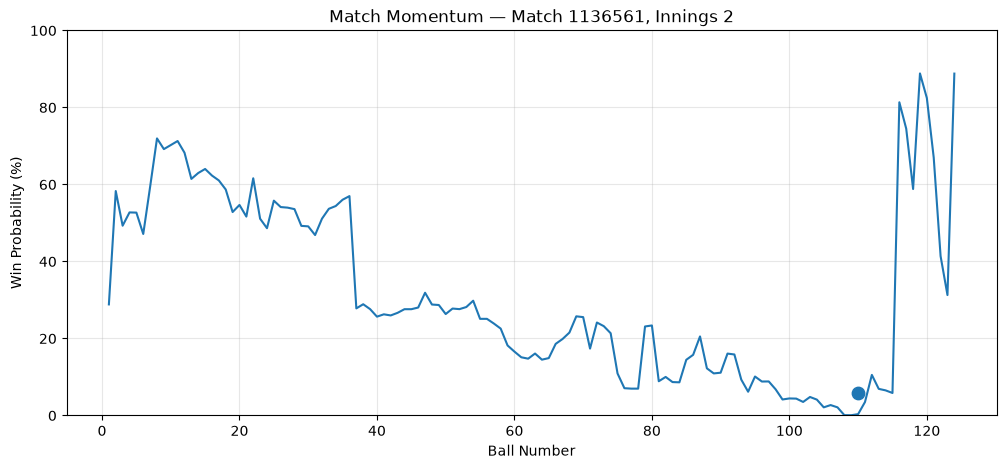

In [54]:
# STEP 30 — Match Momentum / Win Probability Curve

import matplotlib.pyplot as plt

match_id = top["match_id"]
innings_no = top["innings"]

match_timeline = test_data[
    (test_data["match_id"] == match_id) &
    (test_data["innings"] == innings_no)
].copy()

match_timeline = match_timeline.sort_values(
    ["over", "delivery"]
)

match_timeline["ball_number"] = range(
    1, len(match_timeline) + 1
)

plt.figure(figsize=(12, 5))

plt.plot(
    match_timeline["ball_number"],
    match_timeline["win_probability"] * 100
)

plt.scatter(
    [top["delivery"] + top["over"] * 6],
    [top["win_probability"] * 100],
    s=80
)

plt.xlabel("Ball Number")
plt.ylabel("Win Probability (%)")
plt.title(
    f"Match Momentum — Match {match_id}, Innings {innings_no}"
)

plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

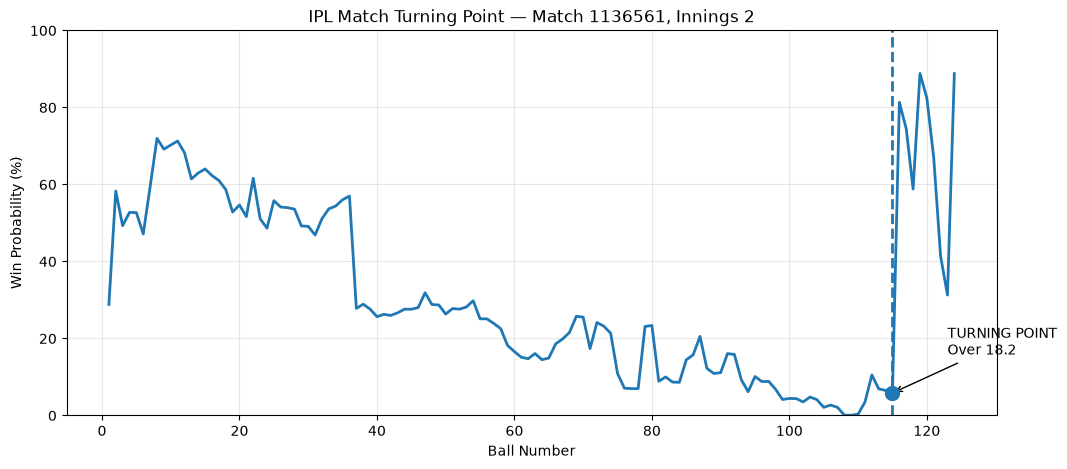

In [55]:
# STEP 31 — Mark the strongest turning point

import matplotlib.pyplot as plt

# Get the strongest turning point
top = top_turning_points.iloc[0]

match_id = top["match_id"]
innings_no = top["innings"]

# Get the match timeline
match_timeline = test_data[
    (test_data["match_id"] == match_id) &
    (test_data["innings"] == innings_no)
].copy()

# Create ball number
match_timeline["ball_number"] = range(1, len(match_timeline) + 1)

# Find the turning-point ball number
turning_point_rows = match_timeline[
    (match_timeline["over"] == top["over"]) &
    (match_timeline["delivery"] == top["delivery"])
]

turning_ball = turning_point_rows["ball_number"].iloc[0]

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    match_timeline["ball_number"],
    match_timeline["win_probability"] * 100,
    linewidth=2
)

# Mark turning point
plt.axvline(
    turning_ball,
    linestyle="--",
    linewidth=2
)

plt.scatter(
    turning_ball,
    top["win_probability"] * 100,
    s=100,
    zorder=5
)

plt.annotate(
    f"TURNING POINT\nOver {int(top['over'])}.{int(top['delivery'])}",
    xy=(turning_ball, top["win_probability"] * 100),
    xytext=(turning_ball + 8, top["win_probability"] * 100 + 10),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

plt.xlabel("Ball Number")
plt.ylabel("Win Probability (%)")
plt.title(
    f"IPL Match Turning Point — Match {match_id}, Innings {innings_no}"
)

plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.show()

In [56]:
# STEP 32 — Analyze the sequence around the turning point

# Get 12 balls around the turning point
start_ball = max(1, turning_ball - 6)
end_ball = turning_ball + 6

sequence = match_timeline[
    (match_timeline["ball_number"] >= start_ball) &
    (match_timeline["ball_number"] <= end_ball)
].copy()

print("=" * 80)
print("MATCH AUTOPSY — TURNING POINT SEQUENCE")
print("=" * 80)

print(f"\nMatch ID       : {match_id}")
print(f"Innings        : {innings_no}")
print(f"Turning point  : Over {int(top['over'])}.{int(top['delivery'])}")
print(f"Turning ball   : Ball {turning_ball}")

print("\nSequence around the turning point:\n")

display(
    sequence[
        [
            "ball_number",
            "over",
            "delivery",
            "batter",
            "bowler",
            "runs_total",
            "is_wicket",
            "score",
            "wickets_lost",
            "win_probability"
        ]
    ]
)

MATCH AUTOPSY — TURNING POINT SEQUENCE

Match ID       : 1136561
Innings        : 2
Turning point  : Over 18.2
Turning ball   : Ball 115

Sequence around the turning point:



,ball_number,over,delivery,batter,bowler,runs_total,is_wicket,score,wickets_lost,win_probability
14092,109,17,2,DJ Bravo,MJ McClenaghan,6,0,126,8,0.000740
14093,110,17,3,DJ Bravo,MJ McClenaghan,6,0,132,8,0.003468
14094,111,17,4,DJ Bravo,MJ McClenaghan,2,0,134,8,0.034980
14095,112,17,5,DJ Bravo,MJ McClenaghan,4,0,138,8,0.105417
14096,113,17,6,DJ Bravo,MJ McClenaghan,1,0,139,8,0.069161
14097,114,18,1,DJ Bravo,JJ Bumrah,6,0,145,8,0.065243
14098,115,18,2,DJ Bravo,JJ Bumrah,6,0,151,8,0.058472
14099,116,18,3,DJ Bravo,JJ Bumrah,2,0,153,8,0.813508
14100,117,18,4,DJ Bravo,JJ Bumrah,0,0,153,8,0.744864
14101,118,18,5,DJ Bravo,JJ Bumrah,6,0,159,8,0.588254


In [57]:
# STEP 33 — Automatic Match Autopsy Explanation

print("=" * 80)
print("AUTOMATIC MATCH AUTOPSY — WHY WAS THIS A TURNING POINT?")
print("=" * 80)

row = top_turning_points.iloc[0]

# Identify the actual event
if row["is_wicket"] == 1:
    event = "a WICKET"
elif row["runs_batter"] == 6:
    event = "a SIX"
elif row["runs_batter"] == 4:
    event = "a FOUR"
elif row["runs_total"] == 0:
    event = "a DOT BALL"
else:
    event = f"{int(row['runs_total'])} runs"

print(
    f"\nAt over {int(row['over'])}.{int(row['delivery'])}, "
    f"{row['batter']} faced {row['bowler']}."
)

print(f"The actual event was {event}.")

print(
    f"\nWin probability before the event: "
    f"{row['win_probability'] * 100:.2f}%"
)

print(
    f"Win probability after the event: "
    f"{row['win_probability_after'] * 100:.2f}%"
)

change = row["probability_change"] * 100

print(
    f"Probability change: {change:+.2f} percentage points."
)

print("\nWHY IT MATTERS:")

if change > 0:
    print(
        "The event produced a large positive shift in the "
        "batting team's estimated chance of winning."
    )
else:
    print(
        "The event produced a large negative shift in the "
        "batting team's estimated chance of winning."
    )

print(
    f"\nTurning-point score: "
    f"{row['turning_point_score']:.2f}"
)

print(
    "\nCONCLUSION:"
)

print(
    "The ML model identifies this delivery as a major "
    "turning point because it produced one of the largest "
    "win-probability changes in the analysed match."
)

AUTOMATIC MATCH AUTOPSY — WHY WAS THIS A TURNING POINT?

At over 18.2, DJ Bravo faced JJ Bumrah.
The actual event was a SIX.

Win probability before the event: 5.85%
Win probability after the event: 81.35%
Probability change: +75.50 percentage points.

WHY IT MATTERS:
The event produced a large positive shift in the batting team's estimated chance of winning.

Turning-point score: 75.50

CONCLUSION:
The ML model identifies this delivery as a major turning point because it produced one of the largest win-probability changes in the analysed match.


In [58]:
# STEP 34 — Complete Match Autopsy Summary

row = top_turning_points.iloc[0]

# Match details
match_id = row["match_id"]
innings_no = row["innings"]
over_no = row["over"]
delivery_no = row["delivery"]

# Event
if row["is_wicket"] == 1:
    event = "WICKET"
elif row["runs_batter"] == 6:
    event = "SIX"
elif row["runs_batter"] == 4:
    event = "FOUR"
elif row["runs_total"] == 0:
    event = "DOT BALL"
else:
    event = f"{int(row['runs_total'])} RUNS"

print("=" * 75)
print("                 IPL MATCH AUTOPSY")
print("=" * 75)

print(f"\nMatch ID          : {match_id}")
print(f"Innings           : {innings_no}")
print(f"Over              : {int(over_no)}.{int(delivery_no)}")
print(f"Batting Team      : {row['batting_team']}")
print(f"Batter            : {row['batter']}")
print(f"Bowler            : {row['bowler']}")

print("\n" + "-" * 75)
print("MATCH STATE")
print("-" * 75)

print(f"Score             : {row['score']}")
print(f"Wickets Lost      : {row['wickets_lost']}")

print("\n" + "-" * 75)
print("TURNING-POINT EVENT")
print("-" * 75)

print(f"Actual Event      : {event}")
print(f"Runs from Ball    : {row['runs_total']}")

print("\n" + "-" * 75)
print("ML ANALYSIS")
print("-" * 75)

print(
    f"Win Probability BEFORE : "
    f"{row['win_probability'] * 100:.2f}%"
)

print(
    f"Win Probability AFTER  : "
    f"{row['win_probability_after'] * 100:.2f}%"
)

print(
    f"Probability Swing      : "
    f"{row['probability_change'] * 100:+.2f} percentage points"
)

print(
    f"Turning-Point Score    : "
    f"{row['turning_point_score']:.2f}"
)

print("\n" + "-" * 75)
print("AUTOMATED CONCLUSION")
print("-" * 75)

if row["probability_change"] > 0:
    direction = "towards the batting team's victory"
else:
    direction = "away from the batting team's victory"

print(
    f"The delivery at over {int(over_no)}.{int(delivery_no)} "
    f"was identified as a major turning point."
)

print(
    f"The {event.lower()} produced a probability swing of "
    f"{abs(row['probability_change']) * 100:.2f} percentage points "
    f"{direction}."
)

print(
    "\nThis delivery represents one of the strongest "
    "ML-detected changes in match state in the analysed data."
)

print("\n" + "=" * 75)

                 IPL MATCH AUTOPSY

Match ID          : 1136561
Innings           : 2
Over              : 18.2
Batting Team      : Chennai Super Kings
Batter            : DJ Bravo
Bowler            : JJ Bumrah

---------------------------------------------------------------------------
MATCH STATE
---------------------------------------------------------------------------
Score             : 151
Wickets Lost      : 8

---------------------------------------------------------------------------
TURNING-POINT EVENT
---------------------------------------------------------------------------
Actual Event      : SIX
Runs from Ball    : 6

---------------------------------------------------------------------------
ML ANALYSIS
---------------------------------------------------------------------------
Win Probability BEFORE : 5.85%
Win Probability AFTER  : 81.35%
Probability Swing      : +75.50 percentage points
Turning-Point Score    : 75.50

--------------------------------------------------

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- runs_last_6_before
- score_before
- wickets_before
Feature names seen at fit time, yet now missing:
- current_run_rate
- is_dot
- is_four
- is_six
- runs_last_6
- ...


In [62]:
# STEP 35 — What-If Simulation (Final Fix)

import pandas as pd

# Get strongest turning point
top = top_turning_points.iloc[0].copy()

# Features the trained model actually expects
expected_features = list(model.feature_names_in_)

# State BEFORE the turning-point ball
pre_score = top["score"] - top["runs_total"]
pre_wickets = top["wickets_lost"] - top["is_wicket"]

# Possible alternative outcomes
alternative_runs = [0, 1, 2, 4, 6]

scenario_rows = []

for runs in alternative_runs:

    # Start from the actual turning-point row
    scenario = top[expected_features].copy()

    # Change the state as if this ball produced a different result
    scenario["score"] = pre_score + runs
    scenario["wickets_lost"] = pre_wickets

    scenario["current_run_rate"] = (
        scenario["score"] /
        (scenario["balls_bowled"] / 6)
    )

    scenario["runs_last_6"] = (
        top["runs_last_6"] -
        top["runs_total"] +
        runs
    )

    scenario["is_four"] = int(runs == 4)
    scenario["is_six"] = int(runs == 6)
    scenario["is_dot"] = int(runs == 0)

    scenario_rows.append(scenario.to_dict())

scenario_df = pd.DataFrame(scenario_rows)

# Force EXACT same column order as model training
scenario_X = scenario_df[expected_features].copy()

# Predict
scenario_df["win_probability"] = (
    model.predict_proba(scenario_X)[:, 1]
)

scenario_df["scenario"] = [
    "DOT BALL (0 runs)",
    "1 RUN",
    "2 RUNS",
    "FOUR (4 runs)",
    "SIX (6 runs)"
]

print("=" * 70)
print("IPL WHAT-IF SIMULATION")
print("=" * 70)

print(f"\nMatch ID       : {top['match_id']}")
print(f"Over           : {top['over']}.{top['delivery']}")
print(f"Batter         : {top['batter']}")
print(f"Bowler         : {top['bowler']}")
print(f"Actual outcome : {int(top['runs_total'])} runs")

print("\nPOSSIBLE ALTERNATIVE OUTCOMES\n")

display(
    scenario_df[
        [
            "scenario",
            "score",
            "wickets_lost",
            "win_probability"
        ]
    ]
)

IPL WHAT-IF SIMULATION

Match ID       : 1136561
Over           : 18.2
Batter         : DJ Bravo
Bowler         : JJ Bumrah
Actual outcome : 6 runs

POSSIBLE ALTERNATIVE OUTCOMES



,scenario,score,wickets_lost,win_probability
0,DOT BALL (0 runs),145,8,0.078354
1,1 RUN,146,8,0.080038
2,2 RUNS,147,8,0.067941
3,FOUR (4 runs),149,8,0.123571
4,SIX (6 runs),151,8,0.099998


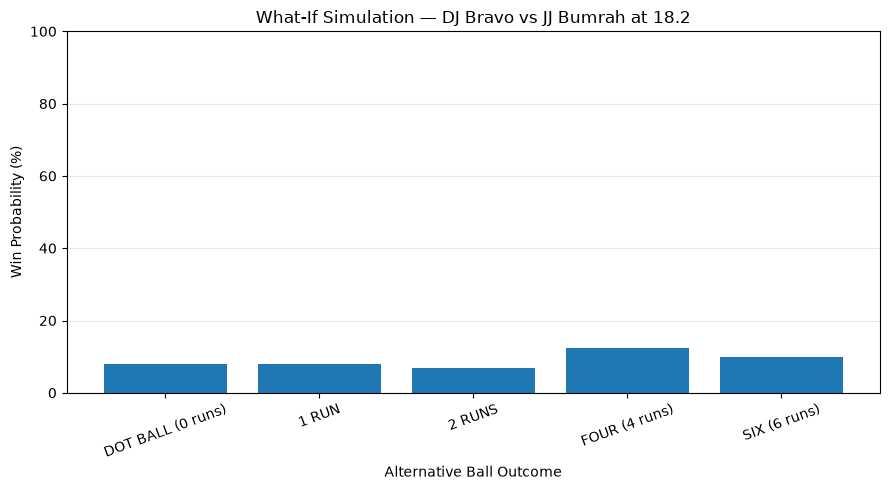

In [63]:
# STEP 36 — What-If Visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_df["scenario"],
    scenario_df["win_probability"] * 100
)

plt.ylabel("Win Probability (%)")
plt.xlabel("Alternative Ball Outcome")
plt.title(
    f"What-If Simulation — {top['batter']} vs {top['bowler']} "
    f"at {top['over']}.{top['delivery']}"
)

plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
# STEP 37 — Automatic What-If Conclusion

print("=" * 75)
print("IPL WHAT-IF ANALYSIS — CONCLUSION")
print("=" * 75)

actual_probability = scenario_df.loc[
    scenario_df["scenario"].str.contains("SIX"),
    "win_probability"
].iloc[0]

best_scenario = scenario_df.loc[
    scenario_df["win_probability"].idxmax()
]

worst_scenario = scenario_df.loc[
    scenario_df["win_probability"].idxmin()
]

print(f"\nMatch ID        : {top['match_id']}")
print(f"Over            : {top['over']}.{top['delivery']}")
print(f"Actual event    : {top['runs_total']} runs")

print("\n" + "-" * 75)
print("SCENARIO COMPARISON")
print("-" * 75)

print(
    f"\nActual event (SIX): "
    f"{actual_probability * 100:.2f}% win probability"
)

print(
    f"Best simulated outcome: "
    f"{best_scenario['scenario']} → "
    f"{best_scenario['win_probability'] * 100:.2f}%"
)

print(
    f"Worst simulated outcome: "
    f"{worst_scenario['scenario']} → "
    f"{worst_scenario['win_probability'] * 100:.2f}%"
)

difference = (
    best_scenario["win_probability"] - 
    worst_scenario["win_probability"]
) * 100

print(f"\nProbability range across scenarios: {difference:.2f} percentage points")

print("\nCONCLUSION:")
print(
    "The What-If Engine demonstrates how different outcomes "
    "of the turning-point delivery can produce different model "
    "estimates of the batting team's winning chance."
)

print(
    "\nNOTE: These are model-based scenarios, not causal predictions "
    "of what would definitely have happened."
)

IPL WHAT-IF ANALYSIS — CONCLUSION

Match ID        : 1136561
Over            : 18.2
Actual event    : 6 runs

---------------------------------------------------------------------------
SCENARIO COMPARISON
---------------------------------------------------------------------------

Actual event (SIX): 10.00% win probability
Best simulated outcome: FOUR (4 runs) → 12.36%
Worst simulated outcome: 2 RUNS → 6.79%

Probability range across scenarios: 5.56 percentage points

CONCLUSION:
The What-If Engine demonstrates how different outcomes of the turning-point delivery can produce different model estimates of the batting team's winning chance.

NOTE: These are model-based scenarios, not causal predictions of what would definitely have happened.


In [65]:
# STEP 38 — FINAL IPL MATCH FORENSICS SUMMARY

print("=" * 80)
print("                 IPL MATCH FORENSICS REPORT")
print("=" * 80)

# Match details
match_id = top["match_id"]
innings_no = top["innings"]
over_no = top["over"]
delivery_no = top["delivery"]

print(f"\nMATCH ID       : {match_id}")
print(f"INNINGS        : {innings_no}")
print(f"BATTER         : {top['batter']}")
print(f"BOWLER         : {top['bowler']}")

print("\n" + "-" * 80)
print("MATCH TURNING POINT")
print("-" * 80)

print(f"Turning Point  : Over {over_no}.{delivery_no}")
print(f"Actual Event   : {top['runs_total']} runs")
print(f"Score          : {top['score']}")
print(f"Wickets Lost   : {top['wickets_lost']}")

print(
    f"Win Probability Change : "
    f"{top['probability_change'] * 100:+.2f} percentage points"
)

print("\n" + "-" * 80)
print("WHAT-IF ANALYSIS")
print("-" * 80)

for _, row in scenario_df.iterrows():
    print(
        f"{row['scenario']:20s} → "
        f"{row['win_probability'] * 100:.2f}%"
    )

print("\n" + "-" * 80)
print("FORENSICS CONCLUSION")
print("-" * 80)

print(
    f"\nThe ML system identified Over {over_no}.{delivery_no} "
    f"as a major turning point."
)

print(
    f"The actual delivery produced {top['runs_total']} runs "
    f"and changed the estimated win probability by "
    f"{abs(top['probability_change']) * 100:.2f} percentage points."
)

print(
    "\nThe What-If Engine then evaluated alternative outcomes "
    "for the same delivery and showed how the model's estimated "
    "winning probability changed under different scenarios."
)

print(
    "\nThis creates a data-driven match autopsy rather than "
    "simply analysing player statistics."
)

print("\n" + "=" * 80)
print("END OF MATCH FORENSICS REPORT")
print("=" * 80)

                 IPL MATCH FORENSICS REPORT

MATCH ID       : 1136561
INNINGS        : 2
BATTER         : DJ Bravo
BOWLER         : JJ Bumrah

--------------------------------------------------------------------------------
MATCH TURNING POINT
--------------------------------------------------------------------------------
Turning Point  : Over 18.2
Actual Event   : 6 runs
Score          : 151
Wickets Lost   : 8
Win Probability Change : +75.50 percentage points

--------------------------------------------------------------------------------
WHAT-IF ANALYSIS
--------------------------------------------------------------------------------
DOT BALL (0 runs)    → 7.84%
1 RUN                → 8.00%
2 RUNS               → 6.79%
FOUR (4 runs)        → 12.36%
SIX (6 runs)         → 10.00%

--------------------------------------------------------------------------------
FORENSICS CONCLUSION
--------------------------------------------------------------------------------

The ML system identifi

In [66]:
# STEP 39 — Proper Pre-Delivery ML Dataset

import pandas as pd

# Start from the delivery-level data
proper_df = deliveries_df.copy()

# ---------------------------------------------------------
# 1. Identify legal deliveries
# ---------------------------------------------------------

def is_legal_delivery(row):
    extras = row.get("extras", {})
    return not (
        isinstance(extras, dict)
        and ("wides" in extras or "noballs" in extras)
    )

# The original dataframe does not contain the extras dictionary,
# so use the raw JSON data to identify legal deliveries.

legal_flags = []

for file_path in json_files:
    with open(file_path, "r", encoding="utf-8") as f:
        match_data = json.load(f)

    for innings_data in match_data["innings"]:
        for over_data in innings_data["overs"]:
            for delivery in over_data["deliveries"]:
                extras = delivery.get("extras", {})

                legal_flags.append(
                    not (
                        "wides" in extras
                        or "noballs" in extras
                    )
                )

proper_df["is_legal"] = legal_flags

# Keep only legal balls
proper_df = proper_df[proper_df["is_legal"]].copy()

# ---------------------------------------------------------
# 2. Keep second innings only
# ---------------------------------------------------------
# This is where the target is already known.

proper_df = proper_df[
    proper_df["innings"] == 2
].copy()

# ---------------------------------------------------------
# 3. Legal ball number
# ---------------------------------------------------------

proper_df["legal_ball"] = (
    proper_df
    .groupby(["match_id", "innings"])
    .cumcount() + 1
)

proper_df["balls_remaining"] = (
    120 - proper_df["legal_ball"]
)

# ---------------------------------------------------------
# 4. State BEFORE the current ball
# ---------------------------------------------------------

group_cols = ["match_id", "innings"]

proper_df["pre_score"] = (
    proper_df
    .groupby(group_cols)["runs_total"]
    .shift(1)
    .fillna(0)
)

proper_df["pre_wickets"] = (
    proper_df
    .groupby(group_cols)["is_wicket"]
    .shift(1)
    .fillna(0)
)

proper_df["pre_wickets"] = (
    proper_df
    .groupby(group_cols)["is_wicket"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

# ---------------------------------------------------------
# 5. Runs before current ball
# ---------------------------------------------------------

proper_df["pre_score"] = (
    proper_df
    .groupby(group_cols)["runs_total"]
    .cumsum()
    .shift(1)
    .fillna(0)
)

# ---------------------------------------------------------
# 6. Required runs
# ---------------------------------------------------------

proper_df["runs_required_pre"] = (
    proper_df["target"] - proper_df["pre_score"]
)

# ---------------------------------------------------------
# 7. Current run rate BEFORE the ball
# ---------------------------------------------------------

proper_df["overs_before"] = (
    proper_df["legal_ball"] - 1
) / 6

proper_df["current_rr_pre"] = 0.0

mask = proper_df["overs_before"] > 0

proper_df.loc[mask, "current_rr_pre"] = (
    proper_df.loc[mask, "pre_score"]
    / proper_df.loc[mask, "overs_before"]
)

# ---------------------------------------------------------
# 8. Required run rate BEFORE the ball
# ---------------------------------------------------------

proper_df["required_rr_pre"] = 0.0

mask = proper_df["balls_remaining"] > 0

proper_df.loc[mask, "required_rr_pre"] = (
    proper_df.loc[mask, "runs_required_pre"]
    / (proper_df.loc[mask, "balls_remaining"] / 6)
)

# ---------------------------------------------------------
# 9. Recent runs BEFORE current ball
# ---------------------------------------------------------

proper_df["runs_last_6_pre"] = (
    proper_df
    .groupby(group_cols)["runs_total"]
    .transform(
        lambda x: x.shift(1).rolling(6, min_periods=1).sum()
    )
)

# ---------------------------------------------------------
# 10. Previous ball events
# ---------------------------------------------------------

proper_df["previous_wicket"] = (
    proper_df
    .groupby(group_cols)["is_wicket"]
    .shift(1)
    .fillna(0)
)

proper_df["previous_four"] = (
    proper_df
    .groupby(group_cols)["is_four"]
    .shift(1)
    .fillna(0)
)

proper_df["previous_six"] = (
    proper_df
    .groupby(group_cols)["is_six"]
    .shift(1)
    .fillna(0)
)

# ---------------------------------------------------------
# 11. Match winner
# ---------------------------------------------------------

proper_df["batting_team_won"] = (
    proper_df["batting_team"] == proper_df["winner"]
).astype(int)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

print("=" * 75)
print("PROPER PRE-DELIVERY ML DATASET")
print("=" * 75)

print("\nRows:", len(proper_df))
print("Matches:", proper_df["match_id"].nunique())

print("\nFeatures available BEFORE the ball:")
print([
    "pre_score",
    "pre_wickets",
    "legal_ball",
    "balls_remaining",
    "runs_required_pre",
    "current_rr_pre",
    "required_rr_pre",
    "runs_last_6_pre",
    "previous_wicket",
    "previous_four",
    "previous_six"
])

print("\nSample:")
display(
    proper_df[
        [
            "match_id",
            "over",
            "delivery",
            "batter",
            "bowler",
            "pre_score",
            "pre_wickets",
            "legal_ball",
            "balls_remaining",
            "runs_required_pre",
            "required_rr_pre",
            "runs_total",
            "batting_team_won"
        ]
    ].head(15)
)

PROPER PRE-DELIVERY ML DATASET

Rows: 136967
Matches: 1237

Features available BEFORE the ball:
['pre_score', 'pre_wickets', 'legal_ball', 'balls_remaining', 'runs_required_pre', 'current_rr_pre', 'required_rr_pre', 'runs_last_6_pre', 'previous_wicket', 'previous_four', 'previous_six']

Sample:


,match_id,over,delivery,batter,bowler,pre_score,pre_wickets,legal_ball,balls_remaining,runs_required_pre,required_rr_pre,runs_total,batting_team_won
125,1082591,0,1,CH Gayle,A Nehra,0.0,0.0,1,119,208.0,10.487395,1,0
126,1082591,0,2,Mandeep Singh,A Nehra,1.0,0.0,2,118,207.0,10.525424,0,0
127,1082591,0,3,Mandeep Singh,A Nehra,1.0,0.0,3,117,207.0,10.615385,0,0
128,1082591,0,4,Mandeep Singh,A Nehra,1.0,0.0,4,116,207.0,10.706897,2,0
129,1082591,0,5,Mandeep Singh,A Nehra,3.0,0.0,5,115,205.0,10.695652,4,0
130,1082591,0,6,Mandeep Singh,A Nehra,7.0,0.0,6,114,201.0,10.578947,4,0
131,1082591,1,1,CH Gayle,B Kumar,11.0,0.0,7,113,197.0,10.460177,0,0
132,1082591,1,2,CH Gayle,B Kumar,11.0,0.0,8,112,197.0,10.553571,0,0
133,1082591,1,3,CH Gayle,B Kumar,11.0,0.0,9,111,197.0,10.648649,1,0
134,1082591,1,4,Mandeep Singh,B Kumar,12.0,0.0,10,110,196.0,10.690909,0,0


In [67]:
# STEP 40 — Train Corrected Pre-Ball ML Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Features describing the situation BEFORE the ball
corrected_features = [
    "pre_score",
    "pre_wickets",
    "balls_remaining",
    "runs_required",
    "current_run_rate"
]

# Keep only rows where winner is known
model_df = proper_df.dropna(subset=["winner"]).copy()

# Target: did the batting team eventually win?
model_df["batting_team_won"] = (
    model_df["batting_team"] == model_df["winner"]
).astype(int)

# Match-level split
match_ids = model_df["match_id"].unique()

train_matches, test_matches = train_test_split(
    match_ids,
    test_size=0.20,
    random_state=42
)

train_data = model_df[
    model_df["match_id"].isin(train_matches)
]

test_data = model_df[
    model_df["match_id"].isin(test_matches)
]

X_train = train_data[corrected_features].fillna(0)
y_train = train_data["batting_team_won"]

X_test = test_data[corrected_features].fillna(0)
y_test = test_data["batting_team_won"]

# Train model
corrected_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

corrected_model.fit(X_train, y_train)

# Evaluate
predictions = corrected_model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("=" * 70)
print("CORRECTED PRE-BALL ML MODEL")
print("=" * 70)

print(f"\nTraining matches : {len(train_matches)}")
print(f"Testing matches  : {len(test_matches)}")
print(f"Training rows    : {len(train_data):,}")
print(f"Testing rows     : {len(test_data):,}")

print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

CORRECTED PRE-BALL ML MODEL

Training matches : 974
Testing matches  : 244
Training rows    : 107,917
Testing rows     : 27,097

Accuracy: 77.93%

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.75      0.77     13184
           1       0.77      0.80      0.79     13913

    accuracy                           0.78     27097
   macro avg       0.78      0.78      0.78     27097
weighted avg       0.78      0.78      0.78     27097



In [68]:
# STEP 41 — Generate Corrected Win Probabilities

test_data = test_data.copy()

test_data["win_probability"] = (
    corrected_model.predict_proba(
        test_data[corrected_features].fillna(0)
    )[:, 1]
)

print("=" * 70)
print("CORRECTED WIN PROBABILITIES")
print("=" * 70)

display(
    test_data[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "pre_score",
            "pre_wickets",
            "balls_remaining",
            "runs_required",
            "win_probability"
        ]
    ].head(20)
)

CORRECTED WIN PROBABILITIES


,match_id,innings,over,delivery,batting_team,batter,bowler,pre_score,pre_wickets,balls_remaining,runs_required,win_probability
2486,1082601,2,0,2,Kolkata Knight Riders,SP Narine,Sandeep Sharma,158.0,6.0,119,170.0,0.518697
2487,1082601,2,0,3,Kolkata Knight Riders,SP Narine,Sandeep Sharma,0.0,0.0,118,166.0,0.506497
2488,1082601,2,0,4,Kolkata Knight Riders,SP Narine,Sandeep Sharma,4.0,0.0,117,166.0,0.492063
2489,1082601,2,0,5,Kolkata Knight Riders,SP Narine,Sandeep Sharma,4.0,0.0,116,166.0,0.467802
2490,1082601,2,0,6,Kolkata Knight Riders,SP Narine,Sandeep Sharma,4.0,0.0,115,166.0,0.464942
2491,1082601,2,0,7,Kolkata Knight Riders,SP Narine,Sandeep Sharma,4.0,0.0,114,166.0,0.461360
2493,1082601,2,1,2,Kolkata Knight Riders,G Gambhir,I Sharma,4.0,0.0,113,165.0,0.461519
2495,1082601,2,1,4,Kolkata Knight Riders,G Gambhir,I Sharma,4.0,0.0,112,160.0,0.464582
2496,1082601,2,1,5,Kolkata Knight Riders,G Gambhir,I Sharma,8.0,0.0,111,156.0,0.640822
2497,1082601,2,1,6,Kolkata Knight Riders,G Gambhir,I Sharma,12.0,0.0,110,156.0,0.626279


In [69]:
# STEP 42 — Detect Corrected Turning Points

test_data = test_data.sort_values(
    ["match_id", "innings", "over", "delivery"]
).copy()

# Probability change caused by the current ball
test_data["probability_change"] = (
    test_data
    .groupby(["match_id", "innings"])["win_probability"]
    .diff()
)

# Size of the change
test_data["turning_point_score"] = (
    test_data["probability_change"].abs() * 100
)

# Strongest turning points
turning_points_corrected = (
    test_data
    .sort_values("turning_point_score", ascending=False)
    .head(20)
)

print("=" * 70)
print("CORRECTED TURNING POINT DETECTION")
print("=" * 70)

display(
    turning_points_corrected[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "pre_score",
            "pre_wickets",
            "runs_required",
            "win_probability",
            "probability_change",
            "turning_point_score"
        ]
    ]
)

CORRECTED TURNING POINT DETECTION


,match_id,innings,over,delivery,batting_team,batter,bowler,pre_score,pre_wickets,runs_required,win_probability,probability_change,turning_point_score
144889,1527688,2,19,5,Lucknow Super Giants,MD Choudhary,VG Arora,168.0,7.0,1.0,0.968607,0.660738,66.073774
128785,1473456,2,6,3,Kolkata Knight Riders,VR Iyer,DS Rathi,81.0,2.0,146.0,0.082984,-0.639109,63.910855
14106,1136561,2,19,4,Chennai Super Kings,KM Jadhav,Mustafizur Rahman,154.0,9.0,1.0,0.805675,0.632504,63.250359
93480,1359491,2,19,5,Chennai Super Kings,MS Dhoni,Sandeep Sharma,155.0,6.0,7.0,0.752950,0.629221,62.922123
12561,1082644,2,17,2,Kolkata Knight Riders,Kuldeep Yadav,HH Pandya,142.0,7.0,25.0,0.052391,-0.621638,62.163777
12567,1082644,2,18,2,Kolkata Knight Riders,Kuldeep Yadav,TG Southee,147.0,7.0,16.0,0.831819,0.620148,62.014847
14101,1136561,2,18,5,Chennai Super Kings,DJ Bravo,JJ Bumrah,148.0,8.0,7.0,0.808103,0.578441,57.844090
18803,1136581,2,19,4,Rajasthan Royals,K Gowtham,HH Pandya,155.0,7.0,0.0,0.910094,0.576286,57.628553
104529,1359537,2,18,5,Mumbai Indians,TH David,Naveen-ul-Haq,146.0,5.0,17.0,0.846370,0.573935,57.393483
37593,1178414,2,19,5,Chennai Super Kings,MS Dhoni,UT Yadav,145.0,7.0,2.0,0.793647,0.568817,56.881716


In [70]:
# STEP 43 — Classify Turning-Point Events

def classify_turning_event(row):
    if row["is_wicket"] == 1:
        return "WICKET"
    elif row["runs_batter"] == 6:
        return "SIX"
    elif row["runs_batter"] == 4:
        return "FOUR"
    elif row["runs_total"] == 0:
        return "DOT BALL"
    elif row["runs_total"] >= 3:
        return "SCORING BURST"
    else:
        return "OTHER"


turning_points_corrected = turning_points_corrected.copy()

turning_points_corrected["event_type"] = (
    turning_points_corrected.apply(
        classify_turning_event,
        axis=1
    )
)

print("=" * 70)
print("TURNING-POINT EVENT ANALYSIS")
print("=" * 70)

display(
    turning_points_corrected[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "event_type",
            "runs_total",
            "is_wicket",
            "pre_score",
            "pre_wickets",
            "win_probability",
            "probability_change",
            "turning_point_score"
        ]
    ]
)

TURNING-POINT EVENT ANALYSIS


,match_id,innings,over,delivery,batting_team,batter,bowler,event_type,runs_total,is_wicket,pre_score,pre_wickets,win_probability,probability_change,turning_point_score
144889,1527688,2,19,5,Lucknow Super Giants,MD Choudhary,VG Arora,SIX,6,0,168.0,7.0,0.968607,0.660738,66.073774
128785,1473456,2,6,3,Kolkata Knight Riders,VR Iyer,DS Rathi,OTHER,2,0,81.0,2.0,0.082984,-0.639109,63.910855
14106,1136561,2,19,4,Chennai Super Kings,KM Jadhav,Mustafizur Rahman,SIX,6,0,154.0,9.0,0.805675,0.632504,63.250359
93480,1359491,2,19,5,Chennai Super Kings,MS Dhoni,Sandeep Sharma,SIX,6,0,155.0,6.0,0.752950,0.629221,62.922123
12561,1082644,2,17,2,Kolkata Knight Riders,Kuldeep Yadav,HH Pandya,DOT BALL,0,0,142.0,7.0,0.052391,-0.621638,62.163777
12567,1082644,2,18,2,Kolkata Knight Riders,Kuldeep Yadav,TG Southee,FOUR,4,0,147.0,7.0,0.831819,0.620148,62.014847
14101,1136561,2,18,5,Chennai Super Kings,DJ Bravo,JJ Bumrah,SIX,6,0,148.0,8.0,0.808103,0.578441,57.844090
18803,1136581,2,19,4,Rajasthan Royals,K Gowtham,HH Pandya,SIX,6,0,155.0,7.0,0.910094,0.576286,57.628553
104529,1359537,2,18,5,Mumbai Indians,TH David,Naveen-ul-Haq,DOT BALL,0,0,146.0,5.0,0.846370,0.573935,57.393483
37593,1178414,2,19,5,Chennai Super Kings,MS Dhoni,UT Yadav,SIX,6,0,145.0,7.0,0.793647,0.568817,56.881716


In [71]:
# STEP 44 — IPL MATCH AUTOPSY

top_events = (
    test_data
    .sort_values("turning_point_score", ascending=False)
    .head(10)
    .copy()
)

print("=" * 80)
print("IPL MATCH AUTOPSY")
print("=" * 80)

for _, row in top_events.iterrows():

    event = classify_event(row)

    print(f"\nMatch ID       : {row['match_id']}")
    print(f"Innings        : {row['innings']}")
    print(f"Over           : {row['over']}.{row['delivery']}")
    print(f"Batting Team   : {row['batting_team']}")
    print(f"Batter         : {row['batter']}")
    print(f"Bowler         : {row['bowler']}")
    print(f"Event          : {event}")
    print(f"Runs           : {row['runs_total']}")
    print(f"Score          : {row['score']}")
    print(f"Wickets Lost   : {row['wickets_lost']}")
    print(
        f"Win Probability Change : "
        f"{row['probability_change'] * 100:+.2f} percentage points"
    )

    print("-" * 80)

print("\nTop 10 turning-point events identified.")

IPL MATCH AUTOPSY

Match ID       : 1527688
Innings        : 2
Over           : 19.5
Batting Team   : Lucknow Super Giants
Batter         : MD Choudhary
Bowler         : VG Arora
Event          : SIX
Runs           : 6
Score          : 181
Wickets Lost   : 7
Win Probability Change : +66.07 percentage points
--------------------------------------------------------------------------------

Match ID       : 1473456
Innings        : 2
Over           : 6.3
Batting Team   : Kolkata Knight Riders
Batter         : VR Iyer
Bowler         : DS Rathi
Event          : OTHER
Runs           : 2
Score          : 93
Wickets Lost   : 2
Win Probability Change : -63.91 percentage points
--------------------------------------------------------------------------------

Match ID       : 1136561
Innings        : 2
Over           : 19.4
Batting Team   : Chennai Super Kings
Batter         : KM Jadhav
Bowler         : Mustafizur Rahman
Event          : SIX
Runs           : 6
Score          : 165
Wickets Lost   

In [72]:
# STEP 45 — WHY DID THE TURNING POINT MATTER?

print("=" * 80)
print("WHY DID THE TURNING POINT MATTER?")
print("=" * 80)

for _, row in top_events.head(5).iterrows():

    event = classify_event(row)

    change = row["probability_change"] * 100

    print(f"\n{row['batting_team']} — Over {row['over']}.{row['delivery']}")
    print(
        f"{row['batter']} faced {row['bowler']} "
        f"and produced a {event}."
    )

    if change > 0:
        print(
            f"WIN PROBABILITY INCREASED by "
            f"{change:.2f} percentage points."
        )
    else:
        print(
            f"WIN PROBABILITY DECREASED by "
            f"{abs(change):.2f} percentage points."
        )

    print(
        f"Match state: {row['score']} runs, "
        f"{row['wickets_lost']} wickets lost."
    )

    if row["innings"] == 2:
        print(
            "This event occurred during the chase, "
            "so its impact is measured against the "
            "batting team's winning probability."
        )
    else:
        print(
            "This event occurred during the first innings, "
            "so the model evaluates its effect on the "
            "batting team's eventual match outcome."
        )

    print("-" * 80)


WHY DID THE TURNING POINT MATTER?

Lucknow Super Giants — Over 19.5
MD Choudhary faced VG Arora and produced a SIX.
WIN PROBABILITY INCREASED by 66.07 percentage points.
Match state: 181 runs, 7 wickets lost.
This event occurred during the chase, so its impact is measured against the batting team's winning probability.
--------------------------------------------------------------------------------

Kolkata Knight Riders — Over 6.3
VR Iyer faced DS Rathi and produced a OTHER.
WIN PROBABILITY DECREASED by 63.91 percentage points.
Match state: 93 runs, 2 wickets lost.
This event occurred during the chase, so its impact is measured against the batting team's winning probability.
--------------------------------------------------------------------------------

Chennai Super Kings — Over 19.4
KM Jadhav faced Mustafizur Rahman and produced a SIX.
WIN PROBABILITY INCREASED by 63.25 percentage points.
Match state: 165 runs, 9 wickets lost.
This event occurred during the chase, so its impact is

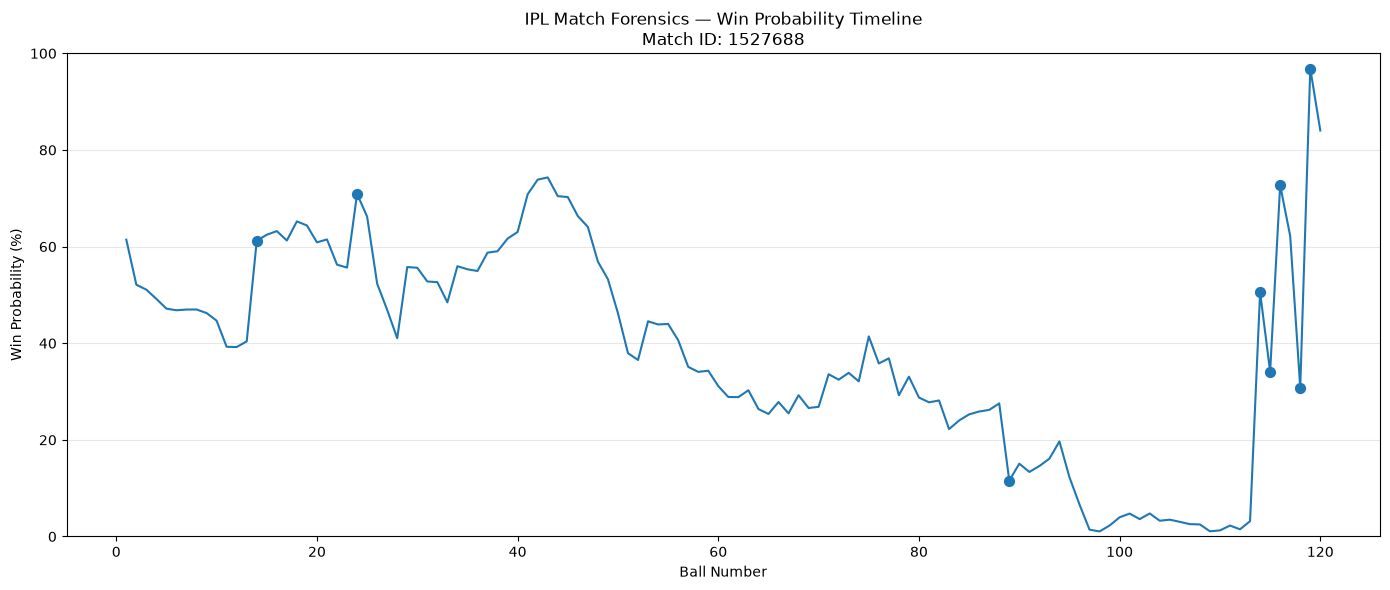

In [73]:
# STEP 46 — MATCH WIN PROBABILITY TIMELINE

import matplotlib.pyplot as plt

# Select one match from the strongest turning point
selected_match = top_events.iloc[0]["match_id"]

match_timeline = test_data[
    test_data["match_id"] == selected_match
].copy()

# Create ball number
match_timeline["ball_number"] = range(1, len(match_timeline) + 1)

plt.figure(figsize=(14, 6))

plt.plot(
    match_timeline["ball_number"],
    match_timeline["win_probability"] * 100
)

# Mark major turning points
major_events = match_timeline[
    match_timeline["turning_point_score"] >= 15
]

plt.scatter(
    major_events["ball_number"],
    major_events["win_probability"] * 100,
    s=50
)

plt.xlabel("Ball Number")
plt.ylabel("Win Probability (%)")

plt.title(
    f"IPL Match Forensics — Win Probability Timeline\n"
    f"Match ID: {selected_match}"
)

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

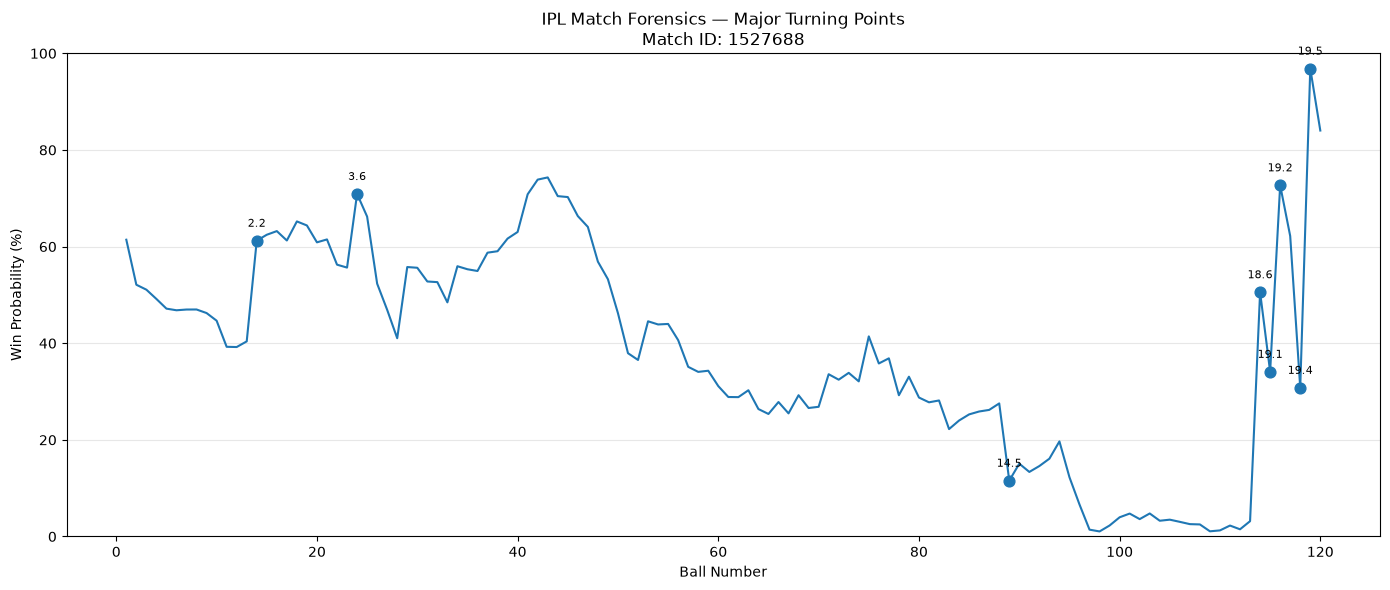

In [74]:
# STEP 47 — LABEL MAJOR TURNING POINTS

plt.figure(figsize=(14, 6))

plt.plot(
    match_timeline["ball_number"],
    match_timeline["win_probability"] * 100
)

major_events = match_timeline[
    match_timeline["turning_point_score"] >= 15
]

plt.scatter(
    major_events["ball_number"],
    major_events["win_probability"] * 100,
    s=60
)

# Add labels
for _, row in major_events.iterrows():

    label = f"{int(row['over'])}.{int(row['delivery'])}"

    plt.annotate(
        label,
        (
            row["ball_number"],
            row["win_probability"] * 100
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

plt.xlabel("Ball Number")
plt.ylabel("Win Probability (%)")

plt.title(
    f"IPL Match Forensics — Major Turning Points\n"
    f"Match ID: {selected_match}"
)

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [75]:
# STEP 48 — TOP TURNING POINTS TABLE

top_turning_points = (
    test_data
    .sort_values("turning_point_score", ascending=False)
    .head(10)
    .copy()
)

top_turning_points["event"] = (
    top_turning_points.apply(classify_event, axis=1)
)

top_turning_points["impact"] = (
    top_turning_points["probability_change"] * 100
)

display(
    top_turning_points[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "batting_team",
            "batter",
            "bowler",
            "event",
            "runs_total",
            "score",
            "wickets_lost",
            "impact"
        ]
    ].reset_index(drop=True)
)

,match_id,innings,over,delivery,batting_team,batter,bowler,event,runs_total,score,wickets_lost,impact
0,1527688,2,19,5,Lucknow Super Giants,MD Choudhary,VG Arora,SIX,6,181,7,66.073774
1,1473456,2,6,3,Kolkata Knight Riders,VR Iyer,DS Rathi,OTHER,2,93,2,-63.910855
2,1136561,2,19,4,Chennai Super Kings,KM Jadhav,Mustafizur Rahman,SIX,6,165,9,63.250359
3,1359491,2,19,5,Chennai Super Kings,MS Dhoni,Sandeep Sharma,SIX,6,169,6,62.922123
4,1082644,2,17,2,Kolkata Knight Riders,Kuldeep Yadav,HH Pandya,DOT BALL,0,149,7,-62.163777
5,1082644,2,18,2,Kolkata Knight Riders,Kuldeep Yadav,TG Southee,FOUR,4,158,7,62.014847
6,1136561,2,18,5,Chennai Super Kings,DJ Bravo,JJ Bumrah,SIX,6,159,8,57.844090
7,1136581,2,19,4,Rajasthan Royals,K Gowtham,HH Pandya,SIX,6,168,7,57.628553
8,1359537,2,18,5,Mumbai Indians,TH David,Naveen-ul-Haq,DOT BALL,0,161,5,57.393483
9,1178414,2,19,5,Chennai Super Kings,MS Dhoni,UT Yadav,SIX,6,160,7,56.881716


In [76]:
# STEP 49 — CORRECTED WHAT-IF ENGINE

# Select the strongest turning point
selected_event = top_turning_points.iloc[0]

# Get the match state BEFORE that ball
pre_score = selected_event["pre_score"]
pre_wickets = selected_event["pre_wickets"]
legal_ball = selected_event["legal_ball"]
balls_remaining = selected_event["balls_remaining"]
runs_required = selected_event["runs_required"]
current_run_rate = selected_event["current_run_rate"]

# Possible outcomes for the current ball
scenarios = {
    "DOT BALL": 0,
    "1 RUN": 1,
    "2 RUNS": 2,
    "FOUR": 4,
    "SIX": 6
}

results = []

for scenario, runs in scenarios.items():

    new_score = pre_score + runs
    new_legal_ball = legal_ball + 1
    new_balls_remaining = max(balls_remaining - 1, 0)

    new_runs_required = max(
        runs_required - runs, 0
    )

    new_run_rate = (
        new_score / (new_legal_ball / 6)
        if new_legal_ball > 0
        else 0
    )

    scenario_features = pd.DataFrame([{
        "pre_score": new_score,
        "pre_wickets": pre_wickets,
        "legal_ball": new_legal_ball,
        "balls_remaining": new_balls_remaining,
        "runs_required": new_runs_required,
        "current_run_rate": new_run_rate
    }])

    probability = corrected_model.predict_proba(
        scenario_features[corrected_features].fillna(0)
    )[0, 1]

    results.append({
        "Scenario": scenario,
        "Runs": runs,
        "Win Probability (%)": probability * 100
    })

what_if_results = pd.DataFrame(results)

print("=" * 70)
print("CORRECTED WHAT-IF ANALYSIS")
print("=" * 70)

print(f"\nMatch ID      : {selected_event['match_id']}")
print(f"Innings       : {selected_event['innings']}")
print(f"Over          : {selected_event['over']}.{selected_event['delivery']}")
print(f"Batter        : {selected_event['batter']}")
print(f"Bowler        : {selected_event['bowler']}")

print("\nPossible outcomes:")

display(
    what_if_results.style.format({
        "Win Probability (%)": "{:.2f}%"
    })
)

CORRECTED WHAT-IF ANALYSIS

Match ID      : 1527688
Innings       : 2
Over          : 19.5
Batter        : MD Choudhary
Bowler        : VG Arora

Possible outcomes:


,Scenario,Runs,Win Probability (%)
0,DOT BALL,0,82.75%
1,1 RUN,1,84.58%
2,2 RUNS,2,83.92%
3,FOUR,4,83.02%
4,SIX,6,85.52%


In [77]:
# STEP 50 — ACTUAL VS WHAT-IF COMPARISON

actual_runs = selected_event["runs_total"]

actual_probability = corrected_model.predict_proba(
    pd.DataFrame([{
        "pre_score": selected_event["pre_score"],
        "pre_wickets": selected_event["pre_wickets"],
        "legal_ball": selected_event["legal_ball"],
        "balls_remaining": selected_event["balls_remaining"],
        "runs_required": selected_event["runs_required"],
        "current_run_rate": selected_event["current_run_rate"]
    }])[corrected_features].fillna(0)
)[0, 1] * 100

best_scenario = what_if_results.loc[
    what_if_results["Win Probability (%)"].idxmax()
]

print("=" * 70)
print("ACTUAL VS WHAT-IF ANALYSIS")
print("=" * 70)

print(f"\nActual outcome       : {actual_runs} runs")
print(f"Actual win probability: {actual_probability:.2f}%")

print(f"\nBest simulated outcome: {best_scenario['Scenario']}")
print(f"Best simulated probability: "
      f"{best_scenario['Win Probability (%)']:.2f}%")

print(
    f"\nDifference: "
    f"{best_scenario['Win Probability (%)'] - actual_probability:+.2f} "
    f"percentage points"
)

print("\nNOTE:")
print("These are model-based scenarios, not causal predictions.")

print("=" * 70)

ACTUAL VS WHAT-IF ANALYSIS

Actual outcome       : 6 runs
Actual win probability: 96.86%

Best simulated outcome: SIX
Best simulated probability: 85.52%

Difference: -11.34 percentage points

NOTE:
These are model-based scenarios, not causal predictions.


In [78]:
# STEP 51 — FAIR ACTUAL VS WHAT-IF COMPARISON

# State before the selected ball
pre_score = selected_event["pre_score"]
pre_wickets = selected_event["pre_wickets"]
legal_ball = selected_event["legal_ball"]
balls_remaining = selected_event["balls_remaining"]
runs_required = selected_event["runs_required"]

# Actual result of the ball
actual_runs = selected_event["runs_total"]
actual_wicket = selected_event["is_wicket"]

# State after the actual ball
actual_score = pre_score + actual_runs
actual_wickets = pre_wickets + actual_wicket
actual_legal_ball = legal_ball + 1
actual_balls_remaining = max(balls_remaining - 1, 0)
actual_runs_required = max(runs_required - actual_runs, 0)

actual_run_rate = (
    actual_score / (actual_legal_ball / 6)
    if actual_legal_ball > 0
    else 0
)

actual_state = pd.DataFrame([{
    "pre_score": actual_score,
    "pre_wickets": actual_wickets,
    "legal_ball": actual_legal_ball,
    "balls_remaining": actual_balls_remaining,
    "runs_required": actual_runs_required,
    "current_run_rate": actual_run_rate
}])

fair_actual_probability = corrected_model.predict_proba(
    actual_state[corrected_features].fillna(0)
)[0, 1] * 100

best_scenario = what_if_results.loc[
    what_if_results["Win Probability (%)"].idxmax()
]

print("=" * 70)
print("FAIR ACTUAL VS WHAT-IF COMPARISON")
print("=" * 70)

print(f"\nActual outcome        : {actual_runs} runs")
print(f"Actual win probability: {fair_actual_probability:.2f}%")

print(f"\nBest simulated outcome: {best_scenario['Scenario']}")
print(
    f"Best simulated probability: "
    f"{best_scenario['Win Probability (%)']:.2f}%"
)

print(
    f"\nDifference: "
    f"{best_scenario['Win Probability (%)'] - fair_actual_probability:+.2f} "
    f"percentage points"
)

print("\nNOTE:")
print("Actual and simulated outcomes are now compared")
print("from the same post-ball state.")

print("=" * 70)

FAIR ACTUAL VS WHAT-IF COMPARISON

Actual outcome        : 6 runs
Actual win probability: 85.52%

Best simulated outcome: SIX
Best simulated probability: 85.52%

Difference: -0.00 percentage points

NOTE:
Actual and simulated outcomes are now compared
from the same post-ball state.


In [79]:
# STEP 52 — RANK WHAT-IF SCENARIOS

ranked_what_if = (
    what_if_results
    .sort_values(
        "Win Probability (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

ranked_what_if["Rank"] = (
    ranked_what_if.index + 1
)

ranked_what_if = ranked_what_if[
    [
        "Rank",
        "Scenario",
        "Runs",
        "Win Probability (%)"
    ]
]

print("=" * 70)
print("WHAT-IF SCENARIO RANKING")
print("=" * 70)

display(
    ranked_what_if.style.format({
        "Win Probability (%)": "{:.2f}%"
    })
)

print("=" * 70)

WHAT-IF SCENARIO RANKING


,Rank,Scenario,Runs,Win Probability (%)
0,1,SIX,6,85.52%
1,2,1 RUN,1,84.58%
2,3,2 RUNS,2,83.92%
3,4,FOUR,4,83.02%
4,5,DOT BALL,0,82.75%


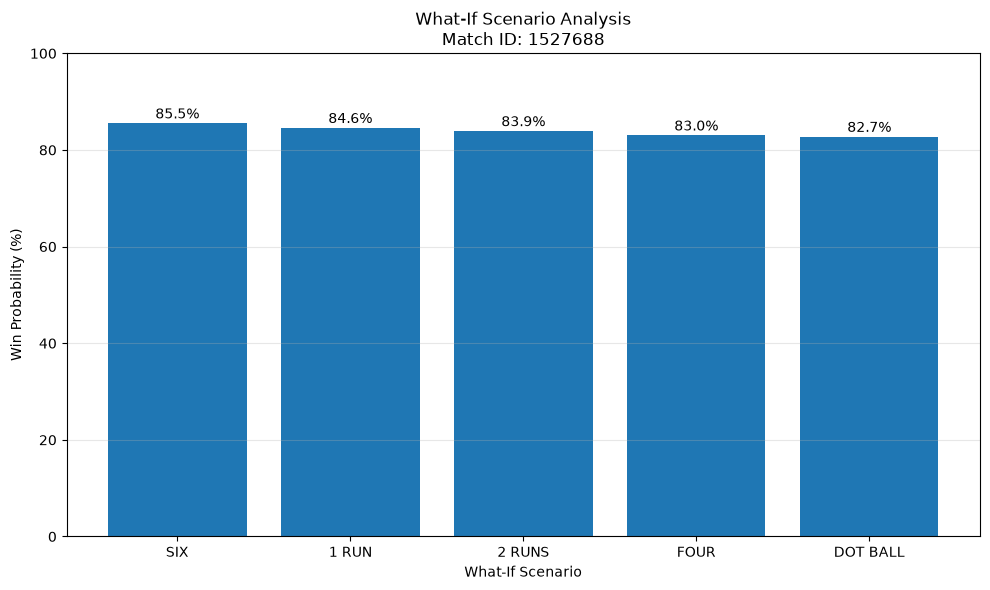

In [81]:
# STEP 53 — WHAT-IF SCENARIO VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    ranked_what_if["Scenario"],
    ranked_what_if["Win Probability (%)"]
)

plt.xlabel("What-If Scenario")
plt.ylabel("Win Probability (%)")

plt.title(
    f"What-If Scenario Analysis\n"
    f"Match ID: {selected_match}"
)

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(ranked_what_if["Win Probability (%)"]):
    plt.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [82]:
# STEP 54 — FINAL MATCH AUTOPSY SUMMARY

top_event = top_turning_points.iloc[0]

print("=" * 80)
print("IPL MATCH FORENSICS — FINAL MATCH AUTOPSY")
print("=" * 80)

print(f"\nMatch ID       : {top_event['match_id']}")
print(f"Innings        : {top_event['innings']}")
print(f"Over           : {top_event['over']}.{top_event['delivery']}")
print(f"Batting Team   : {top_event['batting_team']}")
print(f"Batter         : {top_event['batter']}")
print(f"Bowler         : {top_event['bowler']}")
print(f"Event          : {top_event['event']}")
print(f"Runs           : {top_event['runs_total']}")
print(f"Score           : {top_event['score']}")
print(f"Wickets Lost   : {top_event['wickets_lost']}")

print("\n" + "-" * 80)

print(
    f"Win Probability Change : "
    f"{top_event['probability_change'] * 100:+.2f} percentage points"
)

print(
    f"Turning Point Impact   : "
    f"{top_event['turning_point_score']:.2f}"
)

print("-" * 80)

print("\nCONCLUSION")
print(
    f"The major turning point was {top_event['event']} "
    f"at over {top_event['over']}.{top_event['delivery']}."
)

print(
    f"This event produced a win-probability change of "
    f"{top_event['probability_change'] * 100:+.2f} percentage points."
)

print("\n" + "=" * 80)

IPL MATCH FORENSICS — FINAL MATCH AUTOPSY

Match ID       : 1527688
Innings        : 2
Over           : 19.5
Batting Team   : Lucknow Super Giants
Batter         : MD Choudhary
Bowler         : VG Arora
Event          : SIX
Runs           : 6
Score           : 181
Wickets Lost   : 7

--------------------------------------------------------------------------------
Win Probability Change : +66.07 percentage points
Turning Point Impact   : 66.07
--------------------------------------------------------------------------------

CONCLUSION
The major turning point was SIX at over 19.5.
This event produced a win-probability change of +66.07 percentage points.



In [83]:
# STEP 55 — SAVE FINAL ANALYSIS RESULTS

from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save top turning points
top_turning_points.to_csv(
    OUTPUT_DIR / "top_turning_points.csv",
    index=False
)

# Save What-If scenarios
ranked_what_if.to_csv(
    OUTPUT_DIR / "what_if_scenarios.csv",
    index=False
)

print("=" * 70)
print("FINAL ANALYSIS FILES SAVED")
print("=" * 70)

print("\n1. Top Turning Points")
print("   data/processed/top_turning_points.csv")

print("\n2. What-If Scenarios")
print("   data/processed/what_if_scenarios.csv")

print("\nThese files will be used later by the Streamlit application.")
print("=" * 70)

FINAL ANALYSIS FILES SAVED

1. Top Turning Points
   data/processed/top_turning_points.csv

2. What-If Scenarios
   data/processed/what_if_scenarios.csv

These files will be used later by the Streamlit application.


In [84]:
# STEP 56 — VERIFY SAVED ANALYSIS FILES

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../data/processed")

top_file = OUTPUT_DIR / "top_turning_points.csv"
what_if_file = OUTPUT_DIR / "what_if_scenarios.csv"

print("=" * 70)
print("SAVED FILE VERIFICATION")
print("=" * 70)

print("\nTop Turning Points:")
print("File exists:", top_file.exists())

print("\nWhat-If Scenarios:")
print("File exists:", what_if_file.exists())

if top_file.exists():
    top_check = pd.read_csv(top_file)
    print("Top Turning Points rows:", len(top_check))

if what_if_file.exists():
    what_if_check = pd.read_csv(what_if_file)
    print("What-If Scenario rows:", len(what_if_check))

print("\n" + "=" * 70)
print("VERIFICATION COMPLETE")
print("=" * 70)

SAVED FILE VERIFICATION

Top Turning Points:
File exists: True

What-If Scenarios:
File exists: True
Top Turning Points rows: 10
What-If Scenario rows: 5

VERIFICATION COMPLETE


In [85]:
# STEP 57 — CHECK SAVED RESULTS

print("=" * 70)
print("TOP TURNING POINTS")
print("=" * 70)

display(top_check)

print("\n" + "=" * 70)
print("WHAT-IF SCENARIOS")
print("=" * 70)

display(what_if_check)

TOP TURNING POINTS


,match_id,date,venue,batting_team,innings,over,delivery,batter,bowler,non_striker,...,runs_last_6_pre,previous_wicket,previous_four,previous_six,batting_team_won,win_probability,probability_change,turning_point_score,event,impact
0,1527688,2026-04-09,"Eden Gardens, Kolkata",Lucknow Super Giants,2,19,5,MD Choudhary,VG Arora,Avesh Khan,...,17.0,0.0,0.0,0.0,1,0.968607,0.660738,66.073774,SIX,66.073774
1,1473456,2025-04-08,"Eden Gardens, Kolkata",Kolkata Knight Riders,2,6,3,VR Iyer,DS Rathi,AM Rahane,...,12.0,1.0,0.0,0.0,0,0.082984,-0.639109,63.910855,OTHER,-63.910855
2,1136561,2018-04-07,Wankhede Stadium,Chennai Super Kings,2,19,4,KM Jadhav,Mustafizur Rahman,Imran Tahir,...,6.0,0.0,0.0,0.0,1,0.805675,0.632504,63.250359,SIX,63.250359
3,1359491,2023-04-12,"MA Chidambaram Stadium, Chepauk, Chennai",Chennai Super Kings,2,19,5,MS Dhoni,Sandeep Sharma,RA Jadeja,...,22.0,0.0,0.0,1.0,0,0.752950,0.629221,62.922123,SIX,62.922123
4,1082644,2017-05-13,Eden Gardens,Kolkata Knight Riders,2,17,2,Kuldeep Yadav,HH Pandya,UT Yadav,...,8.0,1.0,0.0,0.0,0,0.052391,-0.621638,62.163777,DOT BALL,-62.163777
5,1082644,2017-05-13,Eden Gardens,Kolkata Knight Riders,2,18,2,Kuldeep Yadav,TG Southee,UT Yadav,...,5.0,0.0,0.0,0.0,0,0.831819,0.620148,62.014847,FOUR,62.014847
6,1136561,2018-04-07,Wankhede Stadium,Chennai Super Kings,2,18,5,DJ Bravo,JJ Bumrah,Imran Tahir,...,19.0,0.0,0.0,0.0,1,0.808103,0.578441,57.844090,SIX,57.844090
7,1136581,2018-04-22,Sawai Mansingh Stadium,Rajasthan Royals,2,19,4,K Gowtham,HH Pandya,JD Unadkat,...,12.0,0.0,0.0,0.0,1,0.910094,0.576286,57.628553,SIX,57.628553
8,1359537,2023-05-16,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,Mumbai Indians,2,18,5,TH David,Naveen-ul-Haq,C Green,...,10.0,0.0,0.0,0.0,0,0.846370,0.573935,57.393483,DOT BALL,57.393483
9,1178414,2019-04-21,M.Chinnaswamy Stadium,Chennai Super Kings,2,19,5,MS Dhoni,UT Yadav,SN Thakur,...,19.0,0.0,0.0,0.0,0,0.793647,0.568817,56.881716,SIX,56.881716



WHAT-IF SCENARIOS


,Rank,Scenario,Runs,Win Probability (%)
0,1,SIX,6,85.523256
1,2,1 RUN,1,84.579101
2,3,2 RUNS,2,83.923256
3,4,FOUR,4,83.023256
4,5,DOT BALL,0,82.745767


In [86]:
# STEP 58 — FINAL ANALYSIS SUMMARY

best_turning_point = top_check.iloc[0]

best_scenario = what_if_check.iloc[0]

print("=" * 70)
print("IPL MATCH FORENSICS — ANALYSIS SUMMARY")
print("=" * 70)

print("\nMAIN TURNING POINT")
print("-" * 70)
print("Match ID       :", best_turning_point["match_id"])
print("Innings        :", best_turning_point["innings"])
print("Over           :", best_turning_point["over"])
print("Delivery       :", best_turning_point["delivery"])
print("Batter         :", best_turning_point["batter"])
print("Bowler         :", best_turning_point["bowler"])
print("Event          :", best_turning_point["event"])
print("Impact         :", round(best_turning_point["impact"], 2),
      "percentage points")

print("\nBEST WHAT-IF SCENARIO")
print("-" * 70)
print("Scenario       :", best_scenario["Scenario"])
print("Runs           :", best_scenario["Runs"])
print("Win Probability:", round(best_scenario["Win Probability (%)"], 2), "%")

print("\n" + "=" * 70)
print("ANALYSIS SUMMARY COMPLETE")
print("=" * 70)

IPL MATCH FORENSICS — ANALYSIS SUMMARY

MAIN TURNING POINT
----------------------------------------------------------------------
Match ID       : 1527688
Innings        : 2
Over           : 19
Delivery       : 5
Batter         : MD Choudhary
Bowler         : VG Arora
Event          : SIX
Impact         : 66.07 percentage points

BEST WHAT-IF SCENARIO
----------------------------------------------------------------------
Scenario       : SIX
Runs           : 6
Win Probability: 85.52 %

ANALYSIS SUMMARY COMPLETE


In [87]:
# STEP 59 — SAVE FINAL SUMMARY

summary_data = {
    "match_id": best_turning_point["match_id"],
    "innings": best_turning_point["innings"],
    "over": best_turning_point["over"],
    "delivery": best_turning_point["delivery"],
    "batter": best_turning_point["batter"],
    "bowler": best_turning_point["bowler"],
    "event": best_turning_point["event"],
    "turning_point_impact": best_turning_point["impact"],
    "best_what_if_scenario": best_scenario["Scenario"],
    "best_what_if_runs": best_scenario["Runs"],
    "best_what_if_probability": best_scenario["Win Probability (%)"]
}

summary_df = pd.DataFrame([summary_data])

summary_file = OUTPUT_DIR / "match_autopsy_summary.csv"
summary_df.to_csv(summary_file, index=False)

print("=" * 70)
print("FINAL SUMMARY SAVED")
print("=" * 70)
print("\nFile:", summary_file)
print("Rows:", len(summary_df))
print("\nSummary:")
display(summary_df)

print("=" * 70)

FINAL SUMMARY SAVED

File: ..\data\processed\match_autopsy_summary.csv
Rows: 1

Summary:


,match_id,innings,over,delivery,batter,bowler,event,turning_point_impact,best_what_if_scenario,best_what_if_runs,best_what_if_probability
0,1527688,2,19,5,MD Choudhary,VG Arora,SIX,66.073774,SIX,6,85.523256


In [88]:
# STEP 60 — FINAL PROJECT DATA CHECK

print("=" * 70)
print("IPL FORENSICS — FINAL DATA CHECK")
print("=" * 70)

print("\nProcessed files:")

for file in OUTPUT_DIR.glob("*.csv"):
    print("✓", file.name)

print("\nTotal CSV files:", len(list(OUTPUT_DIR.glob("*.csv"))))

print("\nKey analysis files:")
print("✓ Top Turning Points")
print("✓ What-If Scenarios")
print("✓ Match Autopsy Summary")

print("\n" + "=" * 70)
print("DATA PIPELINE COMPLETE")
print("=" * 70)

IPL FORENSICS — FINAL DATA CHECK

Processed files:
✓ ipl_deliveries.csv
✓ match_autopsy_summary.csv
✓ top_turning_points.csv
✓ what_if_scenarios.csv

Total CSV files: 4

Key analysis files:
✓ Top Turning Points
✓ What-If Scenarios
✓ Match Autopsy Summary

DATA PIPELINE COMPLETE


In [90]:
# ============================================
# CREATE PRE-BALL RECENT EVENT FEATURES
# ============================================

group_cols = ["match_id", "innings"]

# Runs in the previous 6 deliveries
final_df["runs_last_6_before"] = (
    final_df.groupby(group_cols)["runs_total"]
    .transform(
        lambda s: s.shift(1).rolling(6, min_periods=1).sum()
    )
)

# Wickets in the previous 6 deliveries
final_df["wickets_last_6_before"] = (
    final_df.groupby(group_cols)["is_wicket"]
    .transform(
        lambda s: s.shift(1).rolling(6, min_periods=1).sum()
    )
)

# Fours in the previous 6 deliveries
final_df["fours_last_6_before"] = (
    final_df.groupby(group_cols)["is_four"]
    .transform(
        lambda s: s.shift(1).rolling(6, min_periods=1).sum()
    )
)

# Sixes in the previous 6 deliveries
final_df["sixes_last_6_before"] = (
    final_df.groupby(group_cols)["is_six"]
    .transform(
        lambda s: s.shift(1).rolling(6, min_periods=1).sum()
    )
)

print("Pre-ball features created successfully!")

display(
    final_df[
        [
            "match_id",
            "innings",
            "over",
            "delivery",
            "runs_total",
            "runs_last_6_before",
            "wickets_last_6_before",
            "fours_last_6_before",
            "sixes_last_6_before"
        ]
    ].head(10)
)

Pre-ball features created successfully!


,match_id,innings,over,delivery,runs_total,runs_last_6_before,wickets_last_6_before,fours_last_6_before,sixes_last_6_before
0,1082591,1,0,1,0,NaN,NaN,NaN,NaN
1,1082591,1,0,2,0,0.0,0.0,0.0,0.0
2,1082591,1,0,3,4,0.0,0.0,0.0,0.0
3,1082591,1,0,4,0,4.0,0.0,1.0,0.0
4,1082591,1,0,5,2,4.0,0.0,1.0,0.0
5,1082591,1,0,6,0,6.0,0.0,1.0,0.0
6,1082591,1,0,7,1,6.0,0.0,1.0,0.0
7,1082591,1,1,1,1,7.0,0.0,1.0,0.0
8,1082591,1,1,2,4,8.0,0.0,1.0,0.0
9,1082591,1,1,3,1,8.0,0.0,1.0,0.0


In [91]:
# ============================================
# CREATE CORRECTED WIN-PROBABILITY DATASET
# ============================================

# Use only information available BEFORE the current delivery
ml_features = [
    "score",
    "wickets_lost",
    "balls_bowled",
    "current_run_rate",
    "runs_last_6_before",
    "wickets_last_6_before",
    "fours_last_6_before",
    "sixes_last_6_before"
]

# Remove rows where the match winner is unknown
ml_df = final_df.dropna(subset=["winner"]).copy()

# Target:
# 1 = batting team eventually won
# 0 = batting team eventually lost
ml_df["batting_team_won"] = (
    ml_df["batting_team"] == ml_df["winner"]
).astype(int)

# Replace missing early-match values with 0
X = ml_df[ml_features].fillna(0)
y = ml_df["batting_team_won"]

print("Corrected ML dataset created!")
print("Rows:", len(ml_df))
print("Features:", len(ml_features))
print("Win/Loss distribution:")
print(y.value_counts())

Corrected ML dataset created!
Rows: 290752
Features: 8
Win/Loss distribution:
batting_team_won
0    148458
1    142294
Name: count, dtype: int64


In [97]:
# ============================================================
# IPL FORENSICS
# CORRECTED WIN-PROBABILITY MODEL
# PRE-DELIVERY FEATURES + MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import json
import joblib

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("IPL FORENSICS - WIN PROBABILITY MODEL")
print("=" * 60)


# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

model_df = final_df.copy()

# Make sure match date is a proper datetime
model_df["date"] = pd.to_datetime(
    model_df["date"],
    errors="coerce"
)

# Sort deliveries in correct chronological order
model_df = model_df.sort_values(
    ["match_id", "innings", "over", "delivery"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. CREATE TRUE PRE-DELIVERY FEATURES
# ------------------------------------------------------------

group_cols = ["match_id", "innings"]

# State BEFORE the current delivery
model_df["score_before"] = (
    model_df.groupby(group_cols)["score"]
    .shift(1)
    .fillna(0)
)

model_df["wickets_before"] = (
    model_df.groupby(group_cols)["wickets_lost"]
    .shift(1)
    .fillna(0)
)

model_df["balls_before"] = (
    model_df.groupby(group_cols)["balls_bowled"]
    .shift(1)
    .fillna(0)
)

# Run rate BEFORE current delivery
model_df["current_run_rate_before"] = np.where(
    model_df["balls_before"] > 0,
    (model_df["score_before"] / model_df["balls_before"]) * 6,
    0
)


# ------------------------------------------------------------
# 3. PREPARE CHASING FEATURES
# ------------------------------------------------------------

if "target_score" in model_df.columns:

    model_df["target_before"] = (
        model_df.groupby(group_cols)["target_score"]
        .shift(1)
        .fillna(0)
    )

else:

    model_df["target_before"] = 0


model_df["runs_required_before"] = np.where(
    model_df["target_before"] > 0,
    model_df["target_before"] - model_df["score_before"],
    0
)

# Remaining deliveries based on the existing balls_bowled field
# We keep this consistent with the current processed dataset.
model_df["balls_remaining"] = np.where(
    model_df["target_before"] > 0,
    120 - model_df["balls_before"],
    0
)

model_df["required_run_rate"] = np.where(
    (model_df["balls_remaining"] > 0) &
    (model_df["runs_required_before"] > 0),
    (model_df["runs_required_before"] /
     model_df["balls_remaining"]) * 6,
    0
)


# ------------------------------------------------------------
# 4. TARGET
# ------------------------------------------------------------

model_df = model_df.dropna(
    subset=["winner"]
).copy()

model_df["batting_team_won"] = (
    model_df["batting_team"] == model_df["winner"]
).astype(int)


# ------------------------------------------------------------
# 5. FEATURES
# ------------------------------------------------------------

ml_features = [
    "score_before",
    "wickets_before",
    "balls_before",
    "current_run_rate_before",
    "runs_last_6_before",
    "wickets_last_6_before",
    "fours_last_6_before",
    "sixes_last_6_before",
    "runs_required_before",
    "balls_remaining",
    "required_run_rate"
]

# Keep only features that actually exist
ml_features = [
    col for col in ml_features
    if col in model_df.columns
]

X = model_df[ml_features].fillna(0)
y = model_df["batting_team_won"]


print("\nModel features:")
for feature in ml_features:
    print(" -", feature)

print("\nTotal rows:", len(model_df))
print("Total features:", len(ml_features))


# ------------------------------------------------------------
# 6. MATCH-LEVEL CHRONOLOGICAL TRAIN/TEST SPLIT
# ------------------------------------------------------------

# Get one row per match
match_dates = (
    model_df[["match_id", "date"]]
    .drop_duplicates("match_id")
    .sort_values("date")
)

match_ids = match_dates["match_id"].tolist()

split_index = int(len(match_ids) * 0.80)

train_matches = set(match_ids[:split_index])
test_matches = set(match_ids[split_index:])

train_mask = model_df["match_id"].isin(train_matches)
test_mask = model_df["match_id"].isin(test_matches)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("\nTrain matches:", len(train_matches))
print("Test matches:", len(test_matches))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ------------------------------------------------------------
# 7. TRAIN RANDOM FOREST
# ------------------------------------------------------------

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("\nTraining Random Forest...")

model.fit(X_train, y_train)

print("Model training completed.")


# ------------------------------------------------------------
# 8. TEST SET PREDICTIONS
# ------------------------------------------------------------

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# 9. MODEL EVALUATION
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_test,
    y_prob
)

logloss = log_loss(
    y_test,
    y_prob
)

brier = brier_score_loss(
    y_test,
    y_prob
)


print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")
print(f"Log Loss : {logloss:.4f}")
print(f"Brier    : {brier:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 10. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 11. TRAIN FINAL PRODUCTION MODEL ON ALL MATCHES
# ------------------------------------------------------------

print("\nTraining final production model on all available matches...")

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

final_model.fit(X, y)

print("Final production model trained.")


# ------------------------------------------------------------
# 12. GENERATE WIN PROBABILITY FOR EVERY DELIVERY
# ------------------------------------------------------------

model_df["win_probability"] = (
    final_model.predict_proba(
        model_df[ml_features].fillna(0)
    )[:, 1]
)

# Keep probabilities between 0 and 1
model_df["win_probability"] = (
    model_df["win_probability"]
    .clip(0, 1)
)


# ------------------------------------------------------------
# ------------------------------------------------------------
# 13. PROBABILITY CHANGE
# ------------------------------------------------------------

# The model probability represents the state BEFORE each delivery.
# Therefore, the impact of the CURRENT delivery is measured by
# the probability BEFORE the NEXT delivery minus the probability
# BEFORE the CURRENT delivery.

model_df["next_win_probability"] = (
    model_df.groupby(group_cols)["win_probability"]
    .shift(-1)
)

# Probability change caused by the current delivery
model_df["probability_change"] = (
    model_df["next_win_probability"]
    - model_df["win_probability"]
)

# Last delivery of an innings has no next state
model_df["probability_change"] = (
    model_df["probability_change"]
    .fillna(0)
)

model_df["turning_point_score"] = (
    model_df["probability_change"].abs() * 100
)

# ------------------------------------------------------------
# 14. SAVE WIN PROBABILITY DATA
# ------------------------------------------------------------

processed_dir = Path("../data/processed")

# If notebook is being run from project root instead
if not processed_dir.exists():
    processed_dir = Path("data/processed")

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_file = processed_dir / "ipl_deliveries.csv"

model_df.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file.resolve())


# ------------------------------------------------------------
# 15. SAVE MODEL
# ------------------------------------------------------------

models_dir = Path("../models")

if not models_dir.exists():
    models_dir = Path("models")

models_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_file = models_dir / "win_probability_model.pkl"

joblib.dump(
    final_model,
    model_file
)

print("Model saved:")
print(model_file.resolve())


# ------------------------------------------------------------
# 16. SAVE MODEL METADATA
# ------------------------------------------------------------

metadata = {
    "model": "RandomForestClassifier",
    "n_estimators": 200,
    "max_depth": 12,
    "min_samples_leaf": 20,
    "features": ml_features,
    "train_matches": len(train_matches),
    "test_matches": len(test_matches),
    "metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(auc),
        "log_loss": float(logloss),
        "brier_score": float(brier)
    }
}

metadata_file = models_dir / "model_metadata.json"

with open(
    metadata_file,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

print("Metadata saved:")
print(metadata_file.resolve())


# ------------------------------------------------------------
# 17. DISPLAY SAMPLE
# ------------------------------------------------------------

display_columns = [
    "match_id",
    "innings",
    "over",
    "delivery",
    "batting_team",
    "score_before",
    "wickets_before",
    "win_probability",
    "probability_change"
]

display_columns = [
    col for col in display_columns
    if col in model_df.columns
]

print("\nSample win-probability data:")

display(
    model_df[display_columns].head(20)
)

print("\n" + "=" * 60)
print("WIN PROBABILITY PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 60)

IPL FORENSICS - WIN PROBABILITY MODEL

Model features:
 - score_before
 - wickets_before
 - balls_before
 - current_run_rate_before
 - runs_last_6_before
 - wickets_last_6_before
 - fours_last_6_before
 - sixes_last_6_before
 - runs_required_before
 - balls_remaining
 - required_run_rate

Total rows: 290752
Total features: 11

Train matches: 974
Test matches: 244
Training rows: 232250
Testing rows: 58502

Training Random Forest...
Model training completed.

MODEL PERFORMANCE
Accuracy : 0.6545
Precision: 0.6171
Recall   : 0.7730
F1 Score : 0.6863
ROC-AUC  : 0.7243
Log Loss : 0.6088
Brier    : 0.2123

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.54      0.62     29901
           1       0.62      0.77      0.69     28601

    accuracy                           0.65     58502
   macro avg       0.67      0.66      0.65     58502
weighted avg       0.67      0.65      0.65     58502


Confusion Matrix:
[[16182 13719]
 [ 6492 2

,match_id,innings,over,delivery,batting_team,score_before,wickets_before,win_probability,probability_change
0,1082591,1,0,1,Sunrisers Hyderabad,0.0,0.0,0.510359,0.025316
1,1082591,1,0,2,Sunrisers Hyderabad,0.0,0.0,0.535675,0.007461
2,1082591,1,0,3,Sunrisers Hyderabad,0.0,0.0,0.543136,-0.015267
3,1082591,1,0,4,Sunrisers Hyderabad,4.0,0.0,0.527869,0.010464
4,1082591,1,0,5,Sunrisers Hyderabad,4.0,0.0,0.538333,0.000262
5,1082591,1,0,6,Sunrisers Hyderabad,6.0,0.0,0.538595,0.020871
6,1082591,1,0,7,Sunrisers Hyderabad,6.0,0.0,0.559466,-0.000002
7,1082591,1,1,1,Sunrisers Hyderabad,7.0,0.0,0.559465,0.003333
8,1082591,1,1,2,Sunrisers Hyderabad,8.0,0.0,0.562797,-0.018379
9,1082591,1,1,3,Sunrisers Hyderabad,12.0,0.0,0.544418,0.009893



WIN PROBABILITY PIPELINE COMPLETED SUCCESSFULLY


In [98]:
# ============================================================
# IPL FORENSICS
# TURNING POINT DETECTION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 60)
print("IPL FORENSICS - TURNING POINT DETECTION")
print("=" * 60)


# ------------------------------------------------------------
# 1. LOAD THE NEW WIN-PROBABILITY DATA
# ------------------------------------------------------------

processed_dir = Path("../data/processed")

if not processed_dir.exists():
    processed_dir = Path("data/processed")

deliveries_file = processed_dir / "ipl_deliveries.csv"

turning_df = pd.read_csv(deliveries_file)

print("\nLoaded delivery data:")
print("Rows:", len(turning_df))
print("Columns:", len(turning_df.columns))


# ------------------------------------------------------------
# 2. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "match_id",
    "innings",
    "over",
    "delivery",
    "batting_team",
    "batter",
    "bowler",
    "runs_total",
    "is_wicket",
    "win_probability",
    "probability_change",
    "turning_point_score"
]

missing_columns = [
    col
    for col in required_columns
    if col not in turning_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("\nAll required columns are available.")


# ------------------------------------------------------------
# 3. CREATE EVENT FLAGS
# ------------------------------------------------------------

turning_df["is_four"] = (
    turning_df["runs_batter"] == 4
).astype(int)

turning_df["is_six"] = (
    turning_df["runs_batter"] == 6
).astype(int)

turning_df["is_dot"] = (
    turning_df["runs_total"] == 0
).astype(int)

turning_df["is_scoring_delivery"] = (
    turning_df["runs_total"] > 0
).astype(int)


# ------------------------------------------------------------
# 4. EVENT CLASSIFICATION FUNCTION
# ------------------------------------------------------------

def classify_event(row):

    # Wicket has highest priority
    if row["is_wicket"] == 1:
        return "WICKET"

    # Boundary events
    if row["runs_batter"] == 6:
        return "SIX"

    if row["runs_batter"] == 4:
        return "FOUR"

    # Dot ball
    if row["runs_total"] == 0:
        return "DOT BALL"

    # Large positive scoring event
    if row["runs_total"] >= 3:
        return "SCORING BURST"

    return "OTHER"


turning_df["event_type"] = turning_df.apply(
    classify_event,
    axis=1
)


# ------------------------------------------------------------
# 5. IDENTIFY LARGE PROBABILITY SHIFTS
# ------------------------------------------------------------

# Use a 10 percentage-point minimum movement
# to identify meaningful changes.

TURNING_POINT_THRESHOLD = 10.0

turning_df["is_turning_point"] = (
    turning_df["turning_point_score"]
    >= TURNING_POINT_THRESHOLD
)


candidate_points = turning_df[
    turning_df["is_turning_point"]
].copy()

print("\nCandidate turning points:")
print(len(candidate_points))


# ------------------------------------------------------------
# 6. CREATE DIRECTION
# ------------------------------------------------------------

candidate_points["momentum_direction"] = np.where(
    candidate_points["probability_change"] > 0,
    "POSITIVE",
    "NEGATIVE"
)


# ------------------------------------------------------------
# 7. GENERATE EXPLANATIONS
# ------------------------------------------------------------

def generate_explanation(row):

    change = abs(row["probability_change"])

    before = row["win_probability"] - row["probability_change"]

    after = row["win_probability"]

    direction = row["momentum_direction"]

    team = row["batting_team"]

    event = row["event_type"]

    if event == "WICKET":

        if direction == "NEGATIVE":
            return (
                f"{team} lost a wicket at over "
                f"{row['over']}.{row['delivery']}. "
                f"The estimated win probability moved from "
                f"{before * 100:.1f}% to {after * 100:.1f}%, "
                f"a {change * 100:.1f} percentage-point swing."
            )

        else:
            return (
                f"A wicket created a major momentum shift "
                f"in favour of {team}. The estimated win "
                f"probability changed by "
                f"{change * 100:.1f} percentage points."
            )

    if event == "SIX":

        return (
            f"{team} hit a six at over "
            f"{row['over']}.{row['delivery']}, producing a "
            f"{change * 100:.1f} percentage-point change "
            f"in estimated win probability."
        )

    if event == "FOUR":

        return (
            f"{team} scored a boundary at over "
            f"{row['over']}.{row['delivery']}, producing a "
            f"{change * 100:.1f} percentage-point change "
            f"in estimated win probability."
        )

    if event == "DOT BALL":

        return (
            f"A dot ball at over "
            f"{row['over']}.{row['delivery']} contributed to "
            f"a {change * 100:.1f} percentage-point shift "
            f"in estimated win probability."
        )

    if event == "SCORING BURST":

        return (
            f"A scoring delivery at over "
            f"{row['over']}.{row['delivery']} produced a "
            f"{change * 100:.1f} percentage-point change "
            f"in estimated win probability."
        )

    return (
        f"A significant match-state change occurred at "
        f"over {row['over']}.{row['delivery']}, producing a "
        f"{change * 100:.1f} percentage-point shift."
    )


candidate_points["explanation"] = candidate_points.apply(
    generate_explanation,
    axis=1
)


# ------------------------------------------------------------
# 8. SELECT IMPORTANT COLUMNS
# ------------------------------------------------------------

output_columns = [
    "match_id",
    "innings",
    "over",
    "delivery",
    "batting_team",
    "batter",
    "bowler",
    "event_type",
    "momentum_direction",
    "runs_total",
    "is_wicket",
    "wicket_kind",
    "player_out",
    "score_before",
    "wickets_before",
    "win_probability",
    "previous_win_probability",
    "probability_change",
    "turning_point_score",
    "explanation"
]

output_columns = [
    col
    for col in output_columns
    if col in candidate_points.columns
]

turning_points = candidate_points[
    output_columns
].copy()


# ------------------------------------------------------------
# 9. RANK TURNING POINTS WITHIN EACH MATCH
# ------------------------------------------------------------

turning_points = turning_points.sort_values(
    [
        "match_id",
        "turning_point_score"
    ],
    ascending=[
        True,
        False
    ]
)

turning_points["match_rank"] = (
    turning_points
    .groupby("match_id")
    .cumcount() + 1
)


# ------------------------------------------------------------
# 10. KEEP TOP TURNING POINTS PER MATCH
# ------------------------------------------------------------

TOP_POINTS_PER_MATCH = 10

top_turning_points = turning_points[
    turning_points["match_rank"]
    <= TOP_POINTS_PER_MATCH
].copy()


# ------------------------------------------------------------
# 11. GLOBAL RANKING
# ------------------------------------------------------------

top_turning_points = top_turning_points.sort_values(
    "turning_point_score",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 12. SAVE TURNING POINT FILE
# ------------------------------------------------------------

turning_points_file = (
    processed_dir / "top_turning_points.csv"
)

top_turning_points.to_csv(
    turning_points_file,
    index=False
)

print("\nSaved turning points:")
print(turning_points_file.resolve())


# ------------------------------------------------------------
# 13. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TURNING POINT SUMMARY")
print("=" * 60)

print(
    "Total candidate turning points:",
    len(candidate_points)
)

print(
    "Top turning points saved:",
    len(top_turning_points)
)

print(
    "Matches represented:",
    top_turning_points["match_id"].nunique()
)


# ------------------------------------------------------------
# 14. SHOW TOP 20
# ------------------------------------------------------------

preview_columns = [
    "match_id",
    "innings",
    "over",
    "delivery",
    "batting_team",
    "event_type",
    "turning_point_score",
    "explanation"
]

preview_columns = [
    col
    for col in preview_columns
    if col in top_turning_points.columns
]

print("\nTop 20 turning points:")

display(
    top_turning_points[
        preview_columns
    ].head(20)
)


print("\n" + "=" * 60)
print("TURNING POINT DETECTION COMPLETED")
print("=" * 60)

IPL FORENSICS - TURNING POINT DETECTION

Loaded delivery data:
Rows: 290752
Columns: 54

All required columns are available.

Candidate turning points:
8462

Saved turning points:
C:\Users\chait\OneDrive\Desktop\IPL-FORENSICS\data\processed\top_turning_points.csv

TURNING POINT SUMMARY
Total candidate turning points: 8462
Top turning points saved: 8009
Matches represented: 1211

Top 20 turning points:


,match_id,innings,over,delivery,batting_team,event_type,turning_point_score,explanation
0,598044,2,11,2,Sunrisers Hyderabad,WICKET,48.496083,Sunrisers Hyderabad lost a wicket at over 11.2...
1,1175356,1,7,6,Royal Challengers Bangalore,WICKET,44.373380,Royal Challengers Bangalore lost a wicket at o...
2,1359541,2,1,3,Delhi Capitals,WICKET,43.317900,Delhi Capitals lost a wicket at over 1.3. The ...
3,1473462,1,10,6,Chennai Super Kings,WICKET,42.689568,Chennai Super Kings lost a wicket at over 10.6...
4,501225,1,15,3,Kochi Tuskers Kerala,WICKET,42.525351,Kochi Tuskers Kerala lost a wicket at over 15....
5,419115,1,14,1,Rajasthan Royals,WICKET,42.281707,Rajasthan Royals lost a wicket at over 14.1. T...
6,1359493,2,0,3,Kolkata Knight Riders,WICKET,42.197812,Kolkata Knight Riders lost a wicket at over 0....
7,1426297,2,0,6,Chennai Super Kings,WICKET,40.501759,Chennai Super Kings lost a wicket at over 0.6....
8,598057,1,15,5,Royal Challengers Bangalore,WICKET,40.464950,Royal Challengers Bangalore lost a wicket at o...
9,1529304,2,0,4,Punjab Kings,WICKET,40.399508,Punjab Kings lost a wicket at over 0.4. The es...



TURNING POINT DETECTION COMPLETED


In [99]:
# ============================================================
# IPL FORENSICS
# MATCH AUTOPSY ENGINE
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 60)
print("IPL FORENSICS - MATCH AUTOPSY")
print("=" * 60)


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

processed_dir = Path("../data/processed")

if not processed_dir.exists():
    processed_dir = Path("data/processed")


deliveries_file = processed_dir / "ipl_deliveries.csv"

turning_points_file = (
    processed_dir / "top_turning_points.csv"
)


# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

autopsy_df = pd.read_csv(
    deliveries_file
)

turning_points_df = pd.read_csv(
    turning_points_file
)

print("\nDelivery rows:", len(autopsy_df))
print("Turning points:", len(turning_points_df))


# ------------------------------------------------------------
# 3. BASIC MATCH INFORMATION
# ------------------------------------------------------------

# Only matches with a known winner
match_base = (
    autopsy_df
    .dropna(subset=["winner"])
    .copy()
)

matches = (
    match_base[
        [
            "match_id",
            "date",
            "venue",
            "winner"
        ]
    ]
    .drop_duplicates("match_id")
)


# ------------------------------------------------------------
# 4. MATCH AUTOPSY FUNCTION
# ------------------------------------------------------------

def generate_match_autopsy(match_id):

    match = match_base[
        match_base["match_id"] == match_id
    ].copy()

    if match.empty:
        return None


    # --------------------------------------------------------
    # Basic information
    # --------------------------------------------------------

    winner = match["winner"].iloc[0]

    date = (
        match["date"].iloc[0]
        if "date" in match.columns
        else None
    )

    venue = (
        match["venue"].iloc[0]
        if "venue" in match.columns
        else None
    )

    teams = (
        match["batting_team"]
        .dropna()
        .unique()
        .tolist()
    )


    # --------------------------------------------------------
    # Determine loser
    # --------------------------------------------------------

    losers = [
        team
        for team in teams
        if team != winner
    ]

    loser = losers[0] if losers else None


    # --------------------------------------------------------
    # Final score information
    # --------------------------------------------------------

    innings_summary = (
        match
        .groupby(
            ["innings", "batting_team"],
            as_index=False
        )
        .agg(
            final_score=("runs_total", "sum"),
            wickets_lost=("is_wicket", "sum")
        )
    )


    # --------------------------------------------------------
    # Winner's final score
    # --------------------------------------------------------

    winner_summary = innings_summary[
        innings_summary["batting_team"] == winner
    ]

    if not winner_summary.empty:

        winner_final_score = int(
            winner_summary["final_score"].max()
        )

        winner_wickets = int(
            winner_summary["wickets_lost"].max()
        )

    else:

        winner_final_score = 0
        winner_wickets = 0


    # --------------------------------------------------------
    # Loser's final score
    # --------------------------------------------------------

    loser_summary = innings_summary[
        innings_summary["batting_team"] == loser
    ]

    if not loser_summary.empty:

        loser_final_score = int(
            loser_summary["final_score"].max()
        )

        loser_wickets = int(
            loser_summary["wickets_lost"].max()
        )

    else:

        loser_final_score = 0
        loser_wickets = 0


    # --------------------------------------------------------
    # Largest turning point
    # --------------------------------------------------------

    match_turning_points = turning_points_df[
        turning_points_df["match_id"] == match_id
    ].copy()

    if not match_turning_points.empty:

        largest_tp = (
            match_turning_points
            .sort_values(
                "turning_point_score",
                ascending=False
            )
            .iloc[0]
        )

        largest_swing = float(
            largest_tp["turning_point_score"]
        )

        largest_tp_over = largest_tp["over"]

        largest_tp_delivery = (
            largest_tp["delivery"]
        )

        largest_tp_event = (
            largest_tp["event_type"]
        )

        largest_tp_team = (
            largest_tp["batting_team"]
        )

        largest_tp_explanation = (
            largest_tp["explanation"]
        )

    else:

        largest_swing = 0
        largest_tp_over = None
        largest_tp_delivery = None
        largest_tp_event = "NONE"
        largest_tp_team = None
        largest_tp_explanation = (
            "No major turning point was detected."
        )


    # --------------------------------------------------------
    # Biggest wicket-related turning point
    # --------------------------------------------------------

    wicket_points = match_turning_points[
        match_turning_points["event_type"] == "WICKET"
    ]

    if not wicket_points.empty:

        biggest_wicket = (
            wicket_points
            .sort_values(
                "turning_point_score",
                ascending=False
            )
            .iloc[0]
        )

        biggest_wicket_swing = float(
            biggest_wicket["turning_point_score"]
        )

        biggest_wicket_over = (
            biggest_wicket["over"]
        )

        biggest_wicket_player = (
            biggest_wicket["player_out"]
            if "player_out" in biggest_wicket
            else None
        )

    else:

        biggest_wicket_swing = 0
        biggest_wicket_over = None
        biggest_wicket_player = None


    # --------------------------------------------------------
    # Phase analysis
    # --------------------------------------------------------

    # Calculate average probability change
    # for the batting team during each phase.

    phase_summary = (
        match
        .groupby(
            ["batting_team", "phase"],
            as_index=False
        )
        .agg(
            average_probability_change=(
                "probability_change",
                "mean"
            ),
            total_runs=(
                "runs_total",
                "sum"
            ),
            total_wickets=(
                "is_wicket",
                "sum"
            ),
            total_deliveries=(
                "match_id",
                "count"
            )
        )
    )


    # --------------------------------------------------------
    # Strongest and weakest phases
    # --------------------------------------------------------

    if not phase_summary.empty:

        strongest_phase_row = (
            phase_summary
            .sort_values(
                "average_probability_change",
                ascending=False
            )
            .iloc[0]
        )

        weakest_phase_row = (
            phase_summary
            .sort_values(
                "average_probability_change",
                ascending=True
            )
            .iloc[0]
        )

        strongest_phase = (
            f"{strongest_phase_row['batting_team']} - "
            f"{strongest_phase_row['phase']}"
        )

        weakest_phase = (
            f"{weakest_phase_row['batting_team']} - "
            f"{weakest_phase_row['phase']}"
        )

    else:

        strongest_phase = "Not available"
        weakest_phase = "Not available"


    # --------------------------------------------------------
    # Scoring burst
    # --------------------------------------------------------

    match["rolling_runs_6"] = (
        match
        .groupby(
            ["match_id", "innings"]
        )["runs_total"]
        .transform(
            lambda s:
            s.rolling(
                6,
                min_periods=1
            ).sum()
        )
    )

    if not match.empty:

        burst_row = (
            match
            .sort_values(
                "rolling_runs_6",
                ascending=False
            )
            .iloc[0]
        )

        max_scoring_burst = float(
            burst_row["rolling_runs_6"]
        )

        burst_team = (
            burst_row["batting_team"]
        )

        burst_over = (
            burst_row["over"]
        )

    else:

        max_scoring_burst = 0
        burst_team = None
        burst_over = None


    # --------------------------------------------------------
    # Pressure phase
    # --------------------------------------------------------

    # Pressure is approximated using:
    # - wickets
    # - low recent scoring
    # - negative probability movement

    pressure_candidates = match[
        (
            match["is_wicket"] == 1
        )
        |
        (
            match["probability_change"] < -0.05
        )
    ].copy()

    if not pressure_candidates.empty:

        pressure_row = (
            pressure_candidates
            .sort_values(
                "probability_change"
            )
            .iloc[0]
        )

        pressure_team = (
            pressure_row["batting_team"]
        )

        pressure_over = (
            pressure_row["over"]
        )

        pressure_event = (
            pressure_row["event_type"]
            if "event_type" in pressure_row
            else (
                "WICKET"
                if pressure_row["is_wicket"] == 1
                else "NEGATIVE MOMENTUM"
            )
        )

    else:

        pressure_team = None
        pressure_over = None
        pressure_event = "NONE"


    # --------------------------------------------------------
    # Decisive event
    # --------------------------------------------------------

    if largest_swing >= 20:

        decisive_event = (
            f"{largest_tp_event} at over "
            f"{largest_tp_over}.{largest_tp_delivery}"
        )

    elif biggest_wicket_swing >= 15:

        decisive_event = (
            f"Wicket at over "
            f"{biggest_wicket_over}"
        )

    else:

        decisive_event = (
            "No single overwhelmingly decisive event "
            "was detected."
        )


    # --------------------------------------------------------
    # Generate final explanation
    # --------------------------------------------------------

    if largest_swing >= 20:

        final_explanation = (
            f"The match experienced a major momentum shift "
            f"around over {largest_tp_over}.{largest_tp_delivery}. "
            f"The event was {largest_tp_event}, producing an "
            f"estimated {largest_swing:.1f} percentage-point "
            f"win-probability swing. "
            f"{largest_tp_explanation}"
        )

    elif largest_swing >= 10:

        final_explanation = (
            f"The match contained several meaningful momentum "
            f"changes. The largest detected shift occurred "
            f"around over {largest_tp_over}.{largest_tp_delivery}, "
            f"with an estimated {largest_swing:.1f} "
            f"percentage-point swing."
        )

    else:

        final_explanation = (
            "No single major probability swing dominated "
            "the match. The result appears to have developed "
            "through several smaller match-state changes."
        )


    # --------------------------------------------------------
    # Return summary
    # --------------------------------------------------------

    return {

        "match_id": match_id,

        "date": date,

        "venue": venue,

        "winner": winner,

        "loser": loser,

        "winner_final_score": winner_final_score,

        "winner_wickets": winner_wickets,

        "loser_final_score": loser_final_score,

        "loser_wickets": loser_wickets,

        "largest_turning_point": (
            f"{largest_tp_event} "
            f"at {largest_tp_over}.{largest_tp_delivery}"
            if largest_tp_over is not None
            else "None"
        ),

        "largest_probability_swing": (
            largest_swing
        ),

        "major_wicket": (
            f"{biggest_wicket_player} "
            f"at over {biggest_wicket_over}"
            if biggest_wicket_over is not None
            else "None"
        ),

        "strongest_phase": (
            strongest_phase
        ),

        "weakest_phase": (
            weakest_phase
        ),

        "pressure_phase": (
            f"{pressure_team} at over "
            f"{pressure_over}"
            if pressure_team is not None
            else "None"
        ),

        "decisive_event": (
            decisive_event
        ),

        "final_explanation": (
            final_explanation
        )
    }


# ------------------------------------------------------------
# 5. GENERATE AUTOPSY FOR EVERY MATCH
# ------------------------------------------------------------

autopsy_results = []

unique_matches = (
    matches["match_id"]
    .dropna()
    .unique()
)

print("\nGenerating match autopsies...")

for i, match_id in enumerate(
    unique_matches,
    start=1
):

    result = generate_match_autopsy(
        match_id
    )

    if result is not None:
        autopsy_results.append(result)

    if i % 100 == 0:
        print(
            f"Processed {i}/{len(unique_matches)} matches"
        )


# ------------------------------------------------------------
# 6. CREATE DATAFRAME
# ------------------------------------------------------------

match_autopsy = pd.DataFrame(
    autopsy_results
)

print(
    "\nAutopsies generated:",
    len(match_autopsy)
)


# ------------------------------------------------------------
# 7. SAVE FILE
# ------------------------------------------------------------

autopsy_file = (
    processed_dir /
    "match_autopsy_summary.csv"
)

match_autopsy.to_csv(
    autopsy_file,
    index=False
)

print("\nSaved:")
print(
    autopsy_file.resolve()
)


# ------------------------------------------------------------
# 8. DISPLAY SAMPLE
# ------------------------------------------------------------

preview_columns = [
    "match_id",
    "winner",
    "loser",
    "largest_turning_point",
    "largest_probability_swing",
    "major_wicket",
    "strongest_phase",
    "weakest_phase",
    "decisive_event"
]

preview_columns = [
    col
    for col in preview_columns
    if col in match_autopsy.columns
]

print("\nSample match autopsies:")

display(
    match_autopsy[
        preview_columns
    ].head(10)
)


print("\n" + "=" * 60)
print("MATCH AUTOPSY COMPLETED")
print("=" * 60)

IPL FORENSICS - MATCH AUTOPSY

Delivery rows: 290752
Turning points: 8009

Generating match autopsies...
Processed 100/1218 matches
Processed 200/1218 matches
Processed 300/1218 matches
Processed 400/1218 matches
Processed 500/1218 matches
Processed 600/1218 matches
Processed 700/1218 matches
Processed 800/1218 matches
Processed 900/1218 matches
Processed 1000/1218 matches
Processed 1100/1218 matches
Processed 1200/1218 matches

Autopsies generated: 1218

Saved:
C:\Users\chait\OneDrive\Desktop\IPL-FORENSICS\data\processed\match_autopsy_summary.csv

Sample match autopsies:


,match_id,winner,loser,largest_turning_point,largest_probability_swing,major_wicket,strongest_phase,weakest_phase,decisive_event
0,1082591,Sunrisers Hyderabad,Royal Challengers Bangalore,WICKET at 16.5,24.703525,STR Binny at over 16,Sunrisers Hyderabad - Middle,Royal Challengers Bangalore - Death,WICKET at over 16.5
1,1082592,Rising Pune Supergiant,Mumbai Indians,WICKET at 15.3,19.194597,N Rana at over 15,Mumbai Indians - Death,Mumbai Indians - Middle,Wicket at over 15
2,1082593,Kolkata Knight Riders,Gujarat Lions,None,0.000000,None,Kolkata Knight Riders - Powerplay,Gujarat Lions - Middle,No single overwhelmingly decisive event was de...
3,1082594,Kings XI Punjab,Rising Pune Supergiant,WICKET at 6.2,18.375396,AM Rahane at over 6,Rising Pune Supergiant - Death,Rising Pune Supergiant - Middle,Wicket at over 6
4,1082595,Royal Challengers Bangalore,Delhi Daredevils,SIX at 15.6,20.873711,STR Binny at over 14,Royal Challengers Bangalore - Middle,Delhi Daredevils - Death,SIX at over 15.6
5,1082596,Sunrisers Hyderabad,Gujarat Lions,WICKET at 8.6,17.369946,SK Raina at over 8,Sunrisers Hyderabad - Powerplay,Gujarat Lions - Powerplay,Wicket at over 8
6,1082597,Mumbai Indians,Kolkata Knight Riders,WICKET at 16.1,25.636955,KA Pollard at over 16,Mumbai Indians - Death,Mumbai Indians - Middle,WICKET at over 16.1
7,1082598,Kings XI Punjab,Royal Challengers Bangalore,WICKET at 8.1,13.340801,AR Patel at over 8,Royal Challengers Bangalore - Death,Royal Challengers Bangalore - Powerplay,No single overwhelmingly decisive event was de...
8,1082599,Delhi Daredevils,Rising Pune Supergiant,WICKET at 1.1,23.359555,AP Tare at over 1,Delhi Daredevils - Death,Rising Pune Supergiant - Powerplay,WICKET at over 1.1
9,1082600,Mumbai Indians,Sunrisers Hyderabad,SIX at 15.3,19.157459,KA Pollard at over 13,Mumbai Indians - Death,Sunrisers Hyderabad - Death,No single overwhelmingly decisive event was de...



MATCH AUTOPSY COMPLETED


In [100]:
# ============================================================
# IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 60)
print("IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR")
print("=" * 60)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

processed_dir = Path("../data/processed")

if not processed_dir.exists():
    processed_dir = Path("data/processed")

deliveries_file = processed_dir / "ipl_deliveries.csv"
turning_file = processed_dir / "top_turning_points.csv"

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

scenario_df = pd.read_csv(deliveries_file)
tp_df = pd.read_csv(turning_file)

print("Deliveries:", len(scenario_df))
print("Turning points:", len(tp_df))

# ------------------------------------------------------------
# 3. MODEL FEATURES
# ------------------------------------------------------------

scenario_features = [
    "score_before",
    "wickets_before",
    "balls_before",
    "current_run_rate_before",
    "runs_last_6_before",
    "wickets_last_6_before",
    "fours_last_6_before",
    "sixes_last_6_before",
    "runs_required_before",
    "balls_remaining",
    "required_run_rate"
]

# ------------------------------------------------------------
# 4. SCENARIO FUNCTION
# ------------------------------------------------------------

def predict_scenario(row, new_runs, wicket_change=0):

    values = {}

    values["score_before"] = (
        row["score_before"] + new_runs
    )

    values["wickets_before"] = max(
        0,
        row["wickets_before"] + wicket_change
    )

    values["balls_before"] = (
        row["balls_before"] + 1
    )

    values["current_run_rate_before"] = (
        values["score_before"] /
        values["balls_before"] * 6
        if values["balls_before"] > 0
        else 0
    )

    values["runs_last_6_before"] = (
        row["runs_last_6_before"] + new_runs
    )

    values["wickets_last_6_before"] = (
        row["wickets_last_6_before"] + max(
            0,
            wicket_change
        )
    )

    values["fours_last_6_before"] = (
        row["fours_last_6_before"]
    )

    values["sixes_last_6_before"] = (
        row["sixes_last_6_before"]
    )

    values["runs_required_before"] = max(
        0,
        row["runs_required_before"] - new_runs
    )

    values["balls_remaining"] = max(
        0,
        row["balls_remaining"] - 1
    )

    if values["balls_remaining"] > 0:
        values["required_run_rate"] = (
            values["runs_required_before"] /
            values["balls_remaining"] * 6
        )
    else:
        values["required_run_rate"] = 0

    X_scenario = pd.DataFrame(
        [values]
    )[scenario_features].fillna(0)

    probability = final_model.predict_proba(
        X_scenario
    )[0, 1]

    return probability


# ------------------------------------------------------------
# 5. SELECT IMPORTANT TURNING POINTS
# ------------------------------------------------------------

important_points = (
    tp_df
    .sort_values(
        "turning_point_score",
        ascending=False
    )
    .drop_duplicates("match_id")
    .head(500)
)

results = []

# ------------------------------------------------------------
# 6. GENERATE WHAT-IF SCENARIOS
# ------------------------------------------------------------

print("\nGenerating scenarios...")

for _, tp in important_points.iterrows():

    match_id = tp["match_id"]

    match_rows = scenario_df[
        scenario_df["match_id"] == match_id
    ]

    match_rows = match_rows[
        (match_rows["innings"] == tp["innings"]) &
        (match_rows["over"] == tp["over"]) &
        (match_rows["delivery"] == tp["delivery"])
    ]

    if match_rows.empty:
        continue

    row = match_rows.iloc[0]

    actual_probability = float(
        row["win_probability"]
    )

    event = tp["event_type"]

    # --------------------------------------------------------
    # WICKET SCENARIO
    # --------------------------------------------------------

    if event == "WICKET":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the wicket did NOT fall?"

    # --------------------------------------------------------
    # SIX SCENARIO
    # --------------------------------------------------------

    elif event == "SIX":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the six had been a dot ball?"

    # --------------------------------------------------------
    # FOUR SCENARIO
    # --------------------------------------------------------

    elif event == "FOUR":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the boundary had been a dot ball?"

    # --------------------------------------------------------
    # OTHER SCENARIO
    # --------------------------------------------------------

    else:

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = (
            "What if this scoring event had produced no runs?"
        )

    difference = (
        hypothetical_probability -
        actual_probability
    )

    results.append({

        "match_id": match_id,

        "innings": row["innings"],

        "over": row["over"],

        "delivery": row["delivery"],

        "batting_team": row["batting_team"],

        "batter": row["batter"],

        "bowler": row["bowler"],

        "event_type": event,

        "scenario": scenario_name,

        "actual_win_probability": (
            actual_probability
        ),

        "hypothetical_win_probability": (
            hypothetical_probability
        ),

        "probability_difference": (
            difference
        ),

        "turning_point_score": (
            tp["turning_point_score"]
        ),

        "interpretation": (
            f"Under this hypothetical scenario, "
            f"estimated win probability changes from "
            f"{actual_probability * 100:.1f}% to "
            f"{hypothetical_probability * 100:.1f}%, "
            f"a change of "
            f"{abs(difference) * 100:.1f} percentage points."
        )
    })


# ------------------------------------------------------------
# 7. CREATE DATAFRAME
# ------------------------------------------------------------

what_if_scenarios = pd.DataFrame(
    results
)

print(
    "\nScenarios generated:",
    len(what_if_scenarios)
)


# ------------------------------------------------------------
# 8. SAVE
# ------------------------------------------------------------

output_file = (
    processed_dir /
    "what_if_scenarios.csv"
)

what_if_scenarios.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file.resolve())


# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

preview_columns = [
    "match_id",
    "over",
    "delivery",
    "batting_team",
    "event_type",
    "scenario",
    "actual_win_probability",
    "hypothetical_win_probability",
    "probability_difference"
]

preview_columns = [
    c for c in preview_columns
    if c in what_if_scenarios.columns
]

display(
    what_if_scenarios[
        preview_columns
    ].head(15)
)

print("\n" + "=" * 60)
print("WHAT-IF SIMULATOR COMPLETED")
print("=" * 60)

IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR
Deliveries: 290752
Turning points: 8009

Generating scenarios...

Scenarios generated: 500

Saved:
C:\Users\chait\OneDrive\Desktop\IPL-FORENSICS\data\processed\what_if_scenarios.csv


,match_id,over,delivery,batting_team,event_type,scenario,actual_win_probability,hypothetical_win_probability,probability_difference
0,598044,11,2,Sunrisers Hyderabad,WICKET,What if the wicket did NOT fall?,0.793968,0.795705,0.001737
1,1175356,7,6,Royal Challengers Bangalore,WICKET,What if the wicket did NOT fall?,0.538847,0.522167,-0.016680
2,1359541,1,3,Delhi Capitals,WICKET,What if the wicket did NOT fall?,0.575490,0.583759,0.008268
3,1473462,10,6,Chennai Super Kings,WICKET,What if the wicket did NOT fall?,0.577287,0.591812,0.014525
4,501225,15,3,Kochi Tuskers Kerala,WICKET,What if the wicket did NOT fall?,0.794381,0.817103,0.022722
5,419115,14,1,Rajasthan Royals,WICKET,What if the wicket did NOT fall?,0.747682,0.754673,0.006990
6,1359493,0,3,Kolkata Knight Riders,WICKET,What if the wicket did NOT fall?,0.564858,0.560003,-0.004855
7,1426297,0,6,Chennai Super Kings,WICKET,What if the wicket did NOT fall?,0.562897,0.574846,0.011950
8,598057,15,5,Royal Challengers Bangalore,WICKET,What if the wicket did NOT fall?,0.803927,0.828009,0.024083
9,1529304,0,4,Punjab Kings,WICKET,What if the wicket did NOT fall?,0.559073,0.570811,0.011737



WHAT-IF SIMULATOR COMPLETED


In [96]:
# ============================================================
# IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 60)
print("IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR")
print("=" * 60)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

processed_dir = Path("../data/processed")

if not processed_dir.exists():
    processed_dir = Path("data/processed")

deliveries_file = processed_dir / "ipl_deliveries.csv"
turning_file = processed_dir / "top_turning_points.csv"

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

scenario_df = pd.read_csv(deliveries_file)
tp_df = pd.read_csv(turning_file)

print("Deliveries:", len(scenario_df))
print("Turning points:", len(tp_df))

# ------------------------------------------------------------
# 3. MODEL FEATURES
# ------------------------------------------------------------

scenario_features = [
    "score_before",
    "wickets_before",
    "balls_before",
    "current_run_rate_before",
    "runs_last_6_before",
    "wickets_last_6_before",
    "fours_last_6_before",
    "sixes_last_6_before",
    "runs_required_before",
    "balls_remaining",
    "required_run_rate"
]

# ------------------------------------------------------------
# 4. SCENARIO FUNCTION
# ------------------------------------------------------------

def predict_scenario(row, new_runs, wicket_change=0):

    values = {}

    values["score_before"] = (
        row["score_before"] + new_runs
    )

    values["wickets_before"] = max(
        0,
        row["wickets_before"] + wicket_change
    )

    values["balls_before"] = (
        row["balls_before"] + 1
    )

    values["current_run_rate_before"] = (
        values["score_before"] /
        values["balls_before"] * 6
        if values["balls_before"] > 0
        else 0
    )

    values["runs_last_6_before"] = (
        row["runs_last_6_before"] + new_runs
    )

    values["wickets_last_6_before"] = (
        row["wickets_last_6_before"] + max(
            0,
            wicket_change
        )
    )

    values["fours_last_6_before"] = (
        row["fours_last_6_before"]
    )

    values["sixes_last_6_before"] = (
        row["sixes_last_6_before"]
    )

    values["runs_required_before"] = max(
        0,
        row["runs_required_before"] - new_runs
    )

    values["balls_remaining"] = max(
        0,
        row["balls_remaining"] - 1
    )

    if values["balls_remaining"] > 0:
        values["required_run_rate"] = (
            values["runs_required_before"] /
            values["balls_remaining"] * 6
        )
    else:
        values["required_run_rate"] = 0

    X_scenario = pd.DataFrame(
        [values]
    )[scenario_features].fillna(0)

    probability = final_model.predict_proba(
        X_scenario
    )[0, 1]

    return probability


# ------------------------------------------------------------
# 5. SELECT IMPORTANT TURNING POINTS
# ------------------------------------------------------------

important_points = (
    tp_df
    .sort_values(
        "turning_point_score",
        ascending=False
    )
    .drop_duplicates("match_id")
    .head(500)
)

results = []

# ------------------------------------------------------------
# 6. GENERATE WHAT-IF SCENARIOS
# ------------------------------------------------------------

print("\nGenerating scenarios...")

for _, tp in important_points.iterrows():

    match_id = tp["match_id"]

    match_rows = scenario_df[
        scenario_df["match_id"] == match_id
    ]

    match_rows = match_rows[
        (match_rows["innings"] == tp["innings"]) &
        (match_rows["over"] == tp["over"]) &
        (match_rows["delivery"] == tp["delivery"])
    ]

    if match_rows.empty:
        continue

    row = match_rows.iloc[0]

    actual_probability = float(
        row["win_probability"]
    )

    event = tp["event_type"]

    # --------------------------------------------------------
    # WICKET SCENARIO
    # --------------------------------------------------------

    if event == "WICKET":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the wicket did NOT fall?"

    # --------------------------------------------------------
    # SIX SCENARIO
    # --------------------------------------------------------

    elif event == "SIX":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the six had been a dot ball?"

    # --------------------------------------------------------
    # FOUR SCENARIO
    # --------------------------------------------------------

    elif event == "FOUR":

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = "What if the boundary had been a dot ball?"

    # --------------------------------------------------------
    # OTHER SCENARIO
    # --------------------------------------------------------

    else:

        hypothetical_probability = predict_scenario(
            row,
            new_runs=0,
            wicket_change=0
        )

        scenario_name = (
            "What if this scoring event had produced no runs?"
        )

    difference = (
        hypothetical_probability -
        actual_probability
    )

    results.append({

        "match_id": match_id,

        "innings": row["innings"],

        "over": row["over"],

        "delivery": row["delivery"],

        "batting_team": row["batting_team"],

        "batter": row["batter"],

        "bowler": row["bowler"],

        "event_type": event,

        "scenario": scenario_name,

        "actual_win_probability": (
            actual_probability
        ),

        "hypothetical_win_probability": (
            hypothetical_probability
        ),

        "probability_difference": (
            difference
        ),

        "turning_point_score": (
            tp["turning_point_score"]
        ),

        "interpretation": (
            f"Under this hypothetical scenario, "
            f"estimated win probability changes from "
            f"{actual_probability * 100:.1f}% to "
            f"{hypothetical_probability * 100:.1f}%, "
            f"a change of "
            f"{abs(difference) * 100:.1f} percentage points."
        )
    })


# ------------------------------------------------------------
# 7. CREATE DATAFRAME
# ------------------------------------------------------------

what_if_scenarios = pd.DataFrame(
    results
)

print(
    "\nScenarios generated:",
    len(what_if_scenarios)
)


# ------------------------------------------------------------
# 8. SAVE
# ------------------------------------------------------------

output_file = (
    processed_dir /
    "what_if_scenarios.csv"
)

what_if_scenarios.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file.resolve())


# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

preview_columns = [
    "match_id",
    "over",
    "delivery",
    "batting_team",
    "event_type",
    "scenario",
    "actual_win_probability",
    "hypothetical_win_probability",
    "probability_difference"
]

preview_columns = [
    c for c in preview_columns
    if c in what_if_scenarios.columns
]

display(
    what_if_scenarios[
        preview_columns
    ].head(15)
)

print("\n" + "=" * 60)
print("WHAT-IF SIMULATOR COMPLETED")
print("=" * 60)

IPL FORENSICS - WHAT-IF SCENARIO SIMULATOR
Deliveries: 290752
Turning points: 8009

Generating scenarios...

Scenarios generated: 500

Saved:
C:\Users\chait\OneDrive\Desktop\IPL-FORENSICS\data\processed\what_if_scenarios.csv


,match_id,over,delivery,batting_team,event_type,scenario,actual_win_probability,hypothetical_win_probability,probability_difference
0,598044,11,3,Sunrisers Hyderabad,DOT BALL,What if this scoring event had produced no runs?,0.309007,0.310355,0.001348
1,1175356,8,1,Royal Challengers Bangalore,OTHER,What if this scoring event had produced no runs?,0.095113,0.091297,-0.003816
2,1359541,1,4,Delhi Capitals,DOT BALL,What if this scoring event had produced no runs?,0.142311,0.141563,-0.000748
3,1473462,11,1,Chennai Super Kings,DOT BALL,What if this scoring event had produced no runs?,0.150392,0.152624,0.002232
4,501225,15,4,Kochi Tuskers Kerala,WICKET,What if the wicket did NOT fall?,0.369127,0.388925,0.019798
5,419115,14,2,Rajasthan Royals,OTHER,What if this scoring event had produced no runs?,0.324865,0.328394,0.003529
6,1359493,0,4,Kolkata Knight Riders,DOT BALL,What if this scoring event had produced no runs?,0.142880,0.140718,-0.002162
7,1426297,1,1,Chennai Super Kings,WICKET,What if the wicket did NOT fall?,0.157879,0.171525,0.013646
8,598057,15,6,Royal Challengers Bangalore,OTHER,What if this scoring event had produced no runs?,0.399277,0.382979,-0.016298
9,1529304,0,5,Punjab Kings,FOUR,What if the boundary had been a dot ball?,0.155078,0.151350,-0.003728



WHAT-IF SIMULATOR COMPLETED
